# Fase 3 — Modelo

Tudo neste notebook usa só treino e validação. A ordem importa: primeiro as métricas, porque cada decisão seguinte depende de medir.

In [1]:
import hashlib
import json
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import joblib
import pandas as pd
from matplotlib.colors import LogNorm

from src.features import VetorizadorConteudo
from src.graficos import COR_EIXO, COR_FUNDO, COR_PRINCIPAL, COR_SECUNDARIA, COR_TEXTO_SECUNDARIO, ESCALA_SEQUENCIAL, aplicar_estilo, eixo_br, numero_br, salvar
from src.traducoes import traduzir_token
from src.divisao import simular_cadastros
from src.metricas import aplicar_cota_de_novos, auc_por_item, avaliar, comparar, erros_de_nota, ic_bootstrap, intervalo, montar_protocolo, posicoes_na_lista, top_n_com_novos
from src.recomendador import (
    Recomendador,
    afinidade_cidade,
    afinidade_distancia,
    ajustar_vies_usuarios,
    calcular_componentes,
    escolher_pesos,
    escolher_variante,
    escores_de_produto,
    grade_ao_redor,
    grade_de_pesos,
    modelo_ponderado,
    perfis_de_usuarios,
    similaridade_conteudo,
)
from src.recomendador import pontuar as pontuar_componentes
from src.referencias import PageRankPersonalizado, VizinhosPorItem

PASTA_PROCESSADOS = Path("data/processed")
PASTA_CONJUNTOS = PASTA_PROCESSADOS / "conjuntos"

aplicar_estilo()


def inteiro(valor):
    return f"{valor:,}".replace(",", ".")


locais = pd.read_parquet(PASTA_PROCESSADOS / "locais.parquet")
treino = pd.read_parquet(PASTA_CONJUNTOS / "treino.parquet")
validacao = pd.read_parquet(PASTA_CONJUNTOS / "validacao.parquet")
indice_locais = pd.read_parquet(PASTA_CONJUNTOS / "indice_locais.parquet").set_index("gmap_id")["linha"]
print(f"Treino: {inteiro(len(treino))}; validação: {inteiro(len(validacao))}")

Treino: 213.626; validação: 130.071


## Teoria

**Recomendação baseada em conteúdo.** Cada local vira um vetor com o que se sabe dele (categorias e atributos declaráveis, como "entrega" ou "acessível para cadeira de rodas"), e cada usuário vira um perfil no mesmo espaço, formado pelos locais que ele avaliou. Recomenda-se o que mais se parece com o perfil. Por depender só da descrição do local, a técnica pontua um local que ninguém avaliou, o que as técnicas colaborativas não fazem.

**TF-IDF.** Cada token $t$ de um local $i$ recebe peso $\text{tf}(t,i)\cdot\text{idf}(t)$, com $\text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1$: tokens raros, como uma culinária específica, pesam mais que tokens comuns, como "restaurante". Categorias e atributos formam dois blocos, cada um com TF-IDF e normalização L2 próprios; o vetor final $x_i$ junta os dois e é normalizado de novo.

**Similaridade de cosseno.** $\cos(a, b) = \frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$; com vetores de norma 1, é o produto escalar. A similaridade usada é $\text{sim}(u,i) = \frac{\cos(p_u, x_i) + 1}{2}$, em $[0, 1]$; perfil ou vetor vazio dá 0,5, o valor neutro.

**Perfil ponderado pela nota.** $p_u = \frac{\sum_i w_{ui}\,x_i}{\lVert\sum_i w_{ui}\,x_i\rVert}$, com $w_{ui} = r_{ui} - c_u$. No cenário 1, $c_u$ é a média do usuário: o perfil aponta para o que ele gosta mais que o normal para ele. No cenário 3, $c_u = 3$: com 78% das notas em 4 ou 5, o perfil aponta para o tipo de lugar que ele frequenta, o que prevê aonde ele vai.

**Escores de produto.** A qualidade é a média bayesiana $\text{escore}_i = \frac{v_i R_i + m C}{v_i + m}$, em que $v_i$ e $R_i$ são o número e a média das avaliações do local, $C$ a média do treino e $m$ o percentil 25 das avaliações por local. Um local com poucas avaliações fica perto de $C$, e um local novo recebe exatamente $C$. A popularidade é $\text{pop}_i = \frac{\log(1+v_i)}{\log(1+\max v)}$; um local novo recebe a mediana da cidade, para não ser penalizado só por ser novo.

**Local.** $\text{local}_u(i)$ é a média, nos locais avaliados pelo usuário, de $e^{-d/\tau}$, com $d$ a distância em km até o candidato e $\tau = 200$ km. Para o usuário novo, $d$ é a distância até o centro da cidade informada.

**Combinação linear.** $s(u,i) = \alpha\,\text{sim}(u,i) + \beta\,\text{escore}_i + \gamma\,\text{local}_u(i) + \delta\,\text{pop}_i$, com pesos não negativos que somam 1, escolhidos na validação: 0,1 / 0,2 / 0,5 / 0,2 no cenário 1; 0,05 / 0,19 / 0,475 / 0,285 no cenário 2; $0{,}5\,\text{sim} + 0{,}5\,\text{local}$ para ordenar locais novos no cenário 3, mais a cota de um local novo na lista.

**Por que ordenar em vez de prever nota.** As notas se concentram em 4 e 5 e o local explica só 11% da variância delas, então prever a nota de cada pessoa erra cerca de 1 ponto. O que o usuário vê é a lista; por isso o modelo é avaliado pela ordem (conversão e AUC), e a nota prevista, $\hat r_{ui} = \text{escore}_i + b_u$, com $b_u = \frac{\sum (r_{ui} - \text{escore}_i)}{n_u + 10}$ e limitada a $[1, 5]$, é só informativa.

## Métricas e protocolo

Todas as métricas são as vistas em aula. As definições de cobertura, novidade e serendipidade vêm da literatura geral.

| Métrica | Papel | Como é medida |
|---|---|---|
| Taxa de conversão@10 (`conversao`) | Principal nos cenários 1 e 2 | Fração da lista que o usuário avaliou com nota 4 ou maior no período |
| Curva ROC: AUC de gosto (`auc_gosto`) | Principal nos cenários 1 e 2 | Entre os locais avaliados no período: nota 4 ou maior × nota 3 ou menor. Só usuários com os dois tipos; empate vale meio |
| Taxa de conversão, versão literal (`consumo`) | Reportada | Fração da lista que o usuário avaliou, com qualquer nota |
| Curva ROC: AUC de consumo (`auc_consumo`) | Principal no cenário 3 | Locais convertidos × demais candidatos |
| Correlação de rankings (`spearman`, `kendall`) | Confirmação | Spearman e tau-b de Kendall entre pontuação e nota, por usuário com 3 ou mais avaliações e notas variadas |
| MAE, MSE, RMSE | Só para a nota prevista | Previsão de nota contra a nota real |
| Cobertura do catálogo | Proteção contra listas repetidas | Fração dos candidatos em alguma lista |
| Cobertura dos espaços de usuários e de itens | Decisiva nos cenários 2 e 3 | Usuários com ao menos 10 locais pontuáveis; locais pontuáveis para ao menos 10 usuários |
| Novidade | Acompanhamento | Média de `−log2(fração das avaliações do local no treino)`; local sem avaliação conta como tendo uma |
| Serendipidade | Acompanhamento | Fração da lista que converte e não está na lista óbvia |
| Diversidade | Acompanhamento | Média de `1 − cosseno` entre os pares da lista |
| Intervalos de confiança | Em todas as comparações | 95%, *bootstrap* por usuário, semente 42, pareado nas diferenças; se inclui zero, é empate |

**Protocolo único**, com os mesmos usuários, candidatos e conversões para todo modelo:

- **Candidatos:** locais abertos do treino, ou uma lista informada (cenário 3).
- **Usuários:** do segmento, com ao menos uma conversão entre os candidatos; até 10.000, sorteados se passar disso.
- **Exclusão:** locais já avaliados no treino saem da lista do usuário.
- **Ordenação:** completa, sem amostrar negativos.
- **Empates:** desfeitos por sorteio com semente fixa, para não favorecer a ordem do catálogo.
- **Modelo:** uma função que devolve a matriz usuários × candidatos; `NaN` marca um par que ele não consegue pontuar.
- **Valores por usuário:** ficam disponíveis para os intervalos de confiança.

A célula abaixo confere o protocolo nos dados reais com duas referências simples, só na validação. Nenhuma decisão vem dela. Aqui a lista óbvia da serendipidade é a popularidade, apenas para exercitar o cálculo; a Fase 3 usa popularidade + local.

In [2]:
protocolo_antigo = montar_protocolo(treino, validacao, locais, ["antigo"])
linhas_vetores = indice_locais.loc[protocolo_antigo.candidatos]
vetorizador = VetorizadorConteudo().fit(locais[locais["gmap_id"].isin(treino["gmap_id"])])
vetores_candidatos = vetorizador.transform(locais.iloc[linhas_vetores])


def modelo_aleatorio(usuarios, candidatos):
    return np.random.default_rng(42).random((len(usuarios), len(candidatos)))


def modelo_popularidade(usuarios, candidatos):
    contagem = treino.groupby("gmap_id").size().reindex(candidatos, fill_value=0).to_numpy(dtype=float)
    return np.tile(contagem, (len(usuarios), 1))


print(f"Usuários no protocolo: {inteiro(len(protocolo_antigo.usuarios))}")
print(f"Candidatos: {inteiro(len(protocolo_antigo.candidatos))}")

resultados = {
    "Aleatória": avaliar(protocolo_antigo, modelo_aleatorio, completo=True, com_correlacao=True, vetores=vetores_candidatos, modelo_obvio=modelo_popularidade),
    "Popularidade": avaliar(protocolo_antigo, modelo_popularidade, completo=True, com_correlacao=True, vetores=vetores_candidatos, modelo_obvio=modelo_popularidade),
}
display(pd.DataFrame({nome: resultado.resumo() for nome, resultado in resultados.items()}).round(4))

convertidos_por_usuario = np.asarray((protocolo_antigo.notas >= 4).sum(axis=1)).ravel()
elegiveis = len(protocolo_antigo.candidatos) - np.asarray(protocolo_antigo.ja_avaliados.sum(axis=1)).ravel()
print(f"Conversão@10 esperada ao acaso: {numero_br((convertidos_por_usuario / elegiveis).mean(), 4)}")

for metrica in ["conversao", "auc_gosto", "auc_consumo"]:
    comparacao = comparar(resultados["Popularidade"], resultados["Aleatória"], metrica)
    situacao = "empate" if comparacao["empate"] else "diferença"
    print(f"Popularidade − aleatória em {metrica}: {numero_br(comparacao['diferenca'], 4)} "
          f"(IC 95%: {numero_br(comparacao['inferior'], 4)} a {numero_br(comparacao['superior'], 4)}; {situacao}; {inteiro(comparacao['usuarios'])} usuários)")

Usuários no protocolo: 6.078
Candidatos: 1.419


,Aleatória,Popularidade
conversao,0.0028,0.0204
consumo,0.0035,0.0229
auc_gosto,0.4973,0.4858
spearman,0.0050,-0.0294
kendall,0.0052,-0.0272
auc_consumo,0.5016,0.7394
novidade,11.6097,7.8146
diversidade,0.7616,0.6754
serendipidade,0.0027,0.0000
cobertura_catalogo,1.0000,0.0134


Conversão@10 esperada ao acaso: 0,0029
Popularidade − aleatória em conversao: 0,0175 (IC 95%: 0,0162 a 0,0188; diferença; 6.078 usuários)
Popularidade − aleatória em auc_gosto: -0,0115 (IC 95%: -0,0298 a 0,0071; empate; 2.397 usuários)


Popularidade − aleatória em auc_consumo: 0,2378 (IC 95%: 0,2309 a 0,2448; diferença; 6.078 usuários)


**Leitura:** a ordenação aleatória dá o que se espera do acaso: conversão@10 de 0,0028, contra 0,0029 calculados, e AUCs perto de 0,5. Isso indica que o protocolo não favorece nenhum modelo por construção. A popularidade converte mais (diferença de 0,0175, IC 95% de 0,0162 a 0,0188), mas empata com a aleatória na AUC de gosto (diferença de −0,0115, IC 95% de −0,0298 a 0,0071) e cobre só 1,3% do catálogo. Isso mostra por que a conversão sozinha não basta: ela mede aonde a pessoa vai, não se ela gostou.

**Limitação:** a AUC de gosto vale só para 2.397 dos 6.078 usuários, os que têm notas boas e ruins no período.

## Componentes do modelo

Conferência dos componentes nos dados reais, olhando só o treino. Nenhuma métrica é calculada aqui; a escolha entre as versões vem na seção seguinte.

- **Escore de qualidade:** `escore_i = (v_i·R_i + m·C) / (v_i + m)`, normalizado por `(escore − 1) / 4`. `C` é a média do treino e `m`, um percentil das avaliações por local. O `escore_cidade` usa como prior a média da cidade, suavizada pela mesma fórmula.
- **Perfil do usuário:** `p_u = Σ w_ui·x_i`, normalizado em L2, com `w_ui = nota − centro`; o centro é 3 ou a média do usuário, escolhido na seção seguinte. Só notas neutras: média simples dos vetores.
- **Popularidade:** `pop_i = log(1 + v_i) / log(1 + máx v)`. Local novo recebe a mediana da cidade, ou do catálogo.
- **Local:** fração das avaliações do usuário na cidade do candidato, ou média de `exp(−km/τ)` nos locais avaliados por ele.
- **Previsão de nota:** escore do local + viés regularizado do usuário (`reg = 10`), limitada a [1, 5].

In [3]:
escores, parametros = escores_de_produto(treino, locais)
nome_do_local = locais.set_index("gmap_id")["name"]
avaliados = escores[escores["avaliacoes"] > 0]
print(f"C (média do treino): {numero_br(parametros['C'], 3)}; m (mediana das avaliações por local): {numero_br(parametros['m'], 1)}")
print(f"Locais sem avaliação no treino: {inteiro((escores['avaliacoes'] == 0).sum())}, com escore {numero_br(parametros['C'], 3)}")

nota_cinco = avaliados[avaliados["media"] == 5]
print(f"Locais com média 5: {inteiro(len(nota_cinco))}; avaliações neles: mediana {numero_br(nota_cinco['avaliacoes'].median())}; "
      f"maior escore entre eles: {numero_br(nota_cinco['escore'].max(), 3)}")
colunas = ["nome", "cidade", "avaliacoes", "media", "escore", "popularidade", "posicao_na_cidade"]
tabela_escores = escores.assign(nome=nome_do_local)[colunas]
print("Abertos com maior escore:")
display(tabela_escores[escores["aberto"]].sort_values("escore", ascending=False).head(5).round(3).reset_index(drop=True))
print("Abertos com menor escore:")
display(tabela_escores[escores["aberto"]].sort_values("escore").head(5).round(3).reset_index(drop=True))

priores = escores.groupby("cidade")["prior_cidade"].first()
print(f"Prior das cidades: de {numero_br(priores.min(), 3)} a {numero_br(priores.max(), 3)}")
display(escores[["escore_normalizado", "escore_cidade", "popularidade"]].describe().round(3))
novos_treino = escores[escores["avaliacoes"] == 0]
print(f"Popularidade dos locais sem avaliação: mediana {numero_br(novos_treino['popularidade'].median(), 3)}; "
      f"dos avaliados: mediana {numero_br(avaliados['popularidade'].median(), 3)}")

vies_usuario = ajustar_vies_usuarios(treino, escores["escore"])
print(f"Viés dos usuários: de {numero_br(vies_usuario.min(), 3)} a {numero_br(vies_usuario.max(), 3)}; desvio-padrão {numero_br(vies_usuario.std(), 3)}")

C (média do treino): 4,116; m (mediana das avaliações por local): 75,0
Locais sem avaliação no treino: 216, com escore 4,116
Locais com média 5: 62; avaliações neles: mediana 3; maior escore entre eles: 4,413
Abertos com maior escore:


,nome,cidade,avaliacoes,media,escore,popularidade,posicao_na_cidade
0,Sweet Melissa,Laramie,424,4.788,4.687,0.838,1.0
1,Bar J Chuckwagon Suppers,Wilson,517,4.764,4.682,0.866,1.0
2,Sherrie's Place,Casper,315,4.787,4.658,0.797,1.0
3,Pizza Carrello,Gillette,522,4.709,4.634,0.867,1.0
4,Eggington's,Casper,698,4.670,4.617,0.907,2.0


Abertos com menor escore:


,nome,cidade,avaliacoes,media,escore,popularidade,posicao_na_cidade
0,Sonic Drive-In,Cheyenne,420,2.817,3.014,0.837,204.0
1,McDonald's,Douglas,425,2.981,3.151,0.838,30.0
2,Sonic Drive-In,Evansville,522,3.098,3.226,0.867,11.0
3,Sonic Drive-In,Cheyenne,451,3.109,3.252,0.847,203.0
4,McDonald's,Powell,276,3.018,3.253,0.779,24.0


Prior das cidades: de 3,546 a 4,554


,escore_normalizado,escore_cidade,popularidade
count,1863.000,1863.000,1863.000
mean,0.781,4.131,0.579
std,0.054,0.252,0.179
min,0.437,2.792,0.096
25%,0.763,4.007,0.471
50%,0.781,4.161,0.606
75%,0.812,4.295,0.697
max,0.922,4.737,1.000


Popularidade dos locais sem avaliação: mediana 0,620; dos avaliados: mediana 0,600


Viés dos usuários: de -1,382 a 0,793; desvio-padrão 0,151


In [4]:
inicio = perf_counter()
vetores_todos = vetorizador.transform(locais)
posicao_do_local = indice_locais.to_dict()
perfis, usuarios_perfil = perfis_de_usuarios(treino, vetores_todos, posicao_do_local)
linha_do_perfil = pd.Series(np.arange(len(usuarios_perfil)), index=usuarios_perfil)
usuarios_protocolo, candidatos_protocolo = protocolo_antigo.usuarios, protocolo_antigo.candidatos
sims = similaridade_conteudo(perfis[linha_do_perfil.loc[usuarios_protocolo].to_numpy()], vetores_candidatos)
tempo_conteudo = perf_counter() - inicio

inicio = perf_counter()
por_cidade = afinidade_cidade(treino, locais, usuarios_protocolo, candidatos_protocolo)
tempo_cidade = perf_counter() - inicio

inicio = perf_counter()
por_distancia = afinidade_distancia(treino, locais, usuarios_protocolo, candidatos_protocolo, tau=25)
tempo_distancia = perf_counter() - inicio

normas_perfil = np.sqrt(np.asarray(perfis.multiply(perfis).sum(axis=1)).ravel())
so_neutras = treino.groupby("user_id")["rating"].agg(lambda notas: (notas == 3).all())

componentes = pd.DataFrame(
    {
        "similaridade de conteúdo": sims.ravel(),
        "local por cidade": por_cidade.ravel(),
        "local por distância (τ = 25 km)": por_distancia.ravel(),
    }
)
print(f"Perfis: {inteiro(len(usuarios_perfil))}; só com notas neutras: {inteiro(so_neutras.sum())}; "
      f"com vetor nulo: {inteiro((normas_perfil == 0).sum())}")
print(f"Tempo para {inteiro(len(usuarios_protocolo))} usuários × {inteiro(len(candidatos_protocolo))} candidatos: "
      f"conteúdo {numero_br(tempo_conteudo, 1)} s; cidade {numero_br(tempo_cidade, 1)} s; distância {numero_br(tempo_distancia, 1)} s")
display(componentes.describe().round(3))
print(f"Correlação entre local por cidade e por distância: {numero_br(np.corrcoef(por_cidade.ravel(), por_distancia.ravel())[0, 1], 3)}")

Perfis: 95.365; só com notas neutras: 5.384; com vetor nulo: 5
Tempo para 6.078 usuários × 1.419 candidatos: conteúdo 0,6 s; cidade 0,2 s; distância 0,4 s


,similaridade de conteúdo,local por cidade,local por distância (τ = 25 km)
count,8624682.000,8624682.000,8624682.000
mean,0.663,0.069,0.072
std,0.095,0.220,0.206
min,-0.000,0.000,0.000
25%,0.613,0.000,0.000
50%,0.672,0.000,0.000
75%,0.725,0.000,0.004
max,1.000,1.000,0.999


Correlação entre local por cidade e por distância: 0,958


**Leitura:**

- **A suavização funciona:** os 62 locais com média 5 têm mediana de 3 avaliações, e nenhum passa de um escore de 4,413. O maior escore entre os abertos é 4,687 (Sweet Melissa, média de 4,788 em 424 avaliações). Os menores são redes de fast food com centenas de avaliações, o que confirma que popular não é sinônimo de bom.
- **Local novo não é penalizado:** a popularidade dos locais sem avaliação (mediana de 0,620) fica perto da dos avaliados (0,600).
- **Perfis:** dos 95.365 perfis, 5.384 são só de notas neutras e 5 têm vetor nulo, que resulta em similaridade neutra.
- **Cidade e distância são muito parecidas:** a correlação é de 0,958 com τ = 25 km, então a comparação da próxima etapa pode terminar em empate.
- **Velocidade:** os componentes levam cerca de um segundo para 6.078 usuários, o que torna viável a grade de pesos.

**Atenção ao ler os pesos:** os componentes têm espalhamentos muito diferentes. O desvio-padrão é de 0,054 no escore normalizado, 0,095 na similaridade, 0,179 na popularidade e 0,220 no local por cidade. Um peso maior não significa maior importância: o escore precisa de um peso alto para mudar a ordem tanto quanto o local muda com um peso baixo. Os pesos devem ser lidos pelo efeito nas métricas.

## Pontuação e escolha dos hiperparâmetros (cenário 1)

`s(u,i) = α·sim(u,i) + β·escore_i + γ·local_u(i) + δ·pop_i`, com `sim = (cos + 1) / 2`, pesos não negativos e soma 1.

**Critério, decidido pela usuária:** entre as combinações com conversão@10 de pelo menos 95% da melhor, a de maior AUC de gosto. Exige-se `α ≥ 0,1`, porque a técnica é baseada em conteúdo; o melhor com `α = 0` aparece à parte. A cobertura é sempre reportada.

**Regra para variantes (local, `m`, centro, blocos):** aplica-se o mesmo critério, e a configuração atual só muda se a melhora na AUC de gosto não for empate. Tudo é medido na validação, com o protocolo acima. As grades ficam em `modelos/grades/`; com `REAPROVEITAR = True`, são lidas do arquivo em vez de recalculadas.

In [5]:
PASTA_GRADES = Path("modelos/grades")
PASTA_GRADES.mkdir(parents=True, exist_ok=True)
REAPROVEITAR = True
PESOS_REFERENCIA = (0.1, 0.2, 0.5, 0.2)
NOMES_PESOS = ["alfa", "beta", "gama", "delta"]


def compor(**opcoes):
    return calcular_componentes(treino, locais, protocolo_antigo.usuarios, protocolo_antigo.candidatos, **opcoes)


def avaliar_grade(nome, protocolo, componentes, combinacoes, config):
    # O nome do arquivo inclui a configuração, para nunca reaproveitar a grade de outra.
    chave = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:10]
    caminho = PASTA_GRADES / f"{nome}_{chave}.csv"
    if REAPROVEITAR and caminho.exists():
        return pd.read_csv(caminho)
    linhas = []
    for pesos in combinacoes:
        resumo = avaliar(protocolo, modelo_ponderado(componentes, pesos)).resumo()
        linhas.append(dict(zip(NOMES_PESOS, pesos)) | resumo[["conversao", "consumo", "auc_gosto", "cobertura_catalogo"]].to_dict())
    grade = pd.DataFrame(linhas)
    grade.to_csv(caminho, index=False)
    return grade


def texto_ic(comparacao, casas=4):
    marca = " (empate)" if comparacao["empate"] else ""
    return f"{numero_br(comparacao['diferenca'], casas)} [{numero_br(comparacao['inferior'], casas)}; {numero_br(comparacao['superior'], casas)}]{marca}"


def tabela_contra_base(resultados, base):
    linhas = {}
    for nome, resultado in resultados.items():
        resumo = resultado.resumo()
        linhas[nome] = {
            "conversão@10": round(resumo["conversao"], 4),
            "AUC de gosto": round(resumo["auc_gosto"], 4),
            "cobertura do catálogo": round(resumo["cobertura_catalogo"], 3),
            f"conversão − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "conversao")),
            f"gosto − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "auc_gosto")),
        }
    return pd.DataFrame(linhas).T


def medir(componentes, pesos, **opcoes):
    return avaliar(protocolo_antigo, modelo_ponderado(componentes, pesos), **opcoes)


pd.set_option("display.width", 220, "display.max_colwidth", 60, "display.max_columns", 30)
print(f"Protocolo: {inteiro(len(protocolo_antigo.usuarios))} usuários antigos × {inteiro(len(protocolo_antigo.candidatos))} candidatos")

Protocolo: 6.078 usuários antigos × 1.419 candidatos


### Etapa 1: local

Com os pesos de referência 0,1 / 0,2 / 0,5 / 0,2 (conteúdo / escore / local / popularidade), comparam-se a cidade, a distância e a média das duas.

**Por que esta etapa não decide sozinha:** com pesos fixos, um τ maior achata o componente de local e dá mais força relativa ao escore, um efeito que os próprios pesos também produzem. Nessa comparação, o critério continua preferindo τ maior a cada valor testado. Por isso, a tabela abaixo é só orientação, e a escolha do local é feita junto com os pesos, na etapa 2.

In [6]:
opcoes_local = {"cidade": {"local": "cidade"}}
for tau in [10, 25, 50, 100, 200, 400]:
    opcoes_local[f"distância τ={tau}"] = {"local": "distancia", "tau": tau}
    opcoes_local[f"média τ={tau}"] = {"local": "media", "tau": tau}

resultados_local = {nome: medir(compor(**opcoes), PESOS_REFERENCIA) for nome, opcoes in opcoes_local.items()}
display(tabela_contra_base(resultados_local, "cidade"))
print(f"Com os pesos de referência, o critério apontaria: {escolher_variante(resultados_local, 'cidade', comparar)}")

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − cidade,gosto − cidade
cidade,0.0744,0.5527,0.499,,
distância τ=10,0.0726,0.5495,0.61,"-0,0018 [-0,0034; -0,0003]","-0,0032 [-0,0126; 0,0061] (empate)"
média τ=10,0.0747,0.5509,0.563,"0,0003 [-0,0010; 0,0015] (empate)","-0,0018 [-0,0089; 0,0054] (empate)"
distância τ=25,0.0755,0.5563,0.554,"0,0011 [-0,0002; 0,0023] (empate)","0,0037 [-0,0047; 0,0118] (empate)"
média τ=25,0.0758,0.5523,0.522,"0,0014 [0,0004; 0,0023]","-0,0004 [-0,0057; 0,0049] (empate)"
distância τ=50,0.0765,0.5594,0.514,"0,0021 [0,0010; 0,0032]","0,0068 [-0,0004; 0,0139] (empate)"
média τ=50,0.076,0.553,0.506,"0,0016 [0,0008; 0,0024]","0,0003 [-0,0044; 0,0049] (empate)"
distância τ=100,0.077,0.5613,0.483,"0,0026 [0,0015; 0,0036]","0,0086 [0,0019; 0,0153]"
média τ=100,0.0755,0.5526,0.504,"0,0011 [0,0003; 0,0017]","-0,0000 [-0,0044; 0,0042] (empate)"
distância τ=200,0.0759,0.5634,0.45,"0,0015 [0,0005; 0,0025]","0,0107 [0,0038; 0,0176]"


Com os pesos de referência, o critério apontaria: distância τ=400


**Leitura:** com os pesos fixos, a conversão atinge o máximo em τ = 100 km (0,0770), mas a AUC de gosto continua subindo até τ = 400 km (0,5672), enquanto a cobertura do catálogo cai para 37,8%. Um τ muito grande achata o local, o que favorece o escore. Por isso esta tabela não decide.

### Etapa 2: local e pesos em conjunto

Grade com passo de 0,1 (286 combinações, na ordem conteúdo / escore / local / popularidade) para cada versão de local. O critério se aplica ao conjunto todo. Em caso de empate com a melhor combinação usando cidade, fica a cidade, mais simples de explicar.

In [7]:
versoes_local = {"cidade": {"local": "cidade"}}
for tau in [50, 100, 200, 400, 800]:
    versoes_local[f"distância τ={tau}"] = {"local": "distancia", "tau": tau}
grades_por_local = {
    nome: avaliar_grade("etapa2_pesos", protocolo_antigo, compor(**opcoes), grade_de_pesos(0.1), opcoes)
    for nome, opcoes in versoes_local.items()
}
unida = pd.concat([grade_local.assign(versao=nome) for nome, grade_local in grades_por_local.items()], ignore_index=True)
melhor_geral = unida.loc[unida["alfa"] >= 0.1 - 1e-9, "conversao"].max()
limite_conversao = 0.95 * melhor_geral
linhas_versao = []
for nome, grade_local in grades_por_local.items():
    aptas_versao = grade_local[(grade_local["alfa"] >= 0.1 - 1e-9) & (grade_local["conversao"] >= limite_conversao)]
    if aptas_versao.empty:
        linhas_versao.append({"versão": nome, "aptas": 0})
        continue
    melhor = aptas_versao.sort_values(["auc_gosto", "conversao"], ascending=False).iloc[0]
    linhas_versao.append({"versão": nome, "aptas": len(aptas_versao)} | melhor[NOMES_PESOS + ["conversao", "auc_gosto", "cobertura_catalogo"]].astype(float).to_dict())
tabela_versoes = pd.DataFrame(linhas_versao)
print(f"Melhor conversão no conjunto (α ≥ 0,1): {numero_br(melhor_geral, 4)}; limite de 95%: {numero_br(limite_conversao, 4)}")
display(tabela_versoes.round(4))

vencedora_conjunta = escolher_pesos(unida)
versao_escolhida = vencedora_conjunta["versao"]
pesos_vencedora = tuple(float(vencedora_conjunta[nome]) for nome in NOMES_PESOS)
if versao_escolhida != "cidade":
    linha_cidade = tabela_versoes[tabela_versoes["versão"] == "cidade"].iloc[0]
    if linha_cidade["aptas"] > 0:
        pesos_cidade = tuple(float(linha_cidade[nome]) for nome in NOMES_PESOS)
        com_cidade = medir(compor(local="cidade"), pesos_cidade)
        com_vencedora = medir(compor(**versoes_local[versao_escolhida]), pesos_vencedora)
        comparacoes = {metrica: comparar(com_vencedora, com_cidade, metrica) for metrica in ["conversao", "auc_gosto"]}
        print(f"{versao_escolhida} − cidade: conversão {texto_ic(comparacoes['conversao'])}; gosto {texto_ic(comparacoes['auc_gosto'])}")
        if comparacoes["auc_gosto"]["empate"] and comparacoes["conversao"]["empate"]:
            versao_escolhida, pesos_vencedora = "cidade", pesos_cidade
print(f"Versão de local escolhida: {versao_escolhida}")

configuracao = dict(versoes_local[versao_escolhida])
componentes_base = compor(**configuracao)
grade = grades_por_local[versao_escolhida]
escolha = grade[grade[NOMES_PESOS].sub(list(pesos_vencedora)).abs().sum(axis=1) < 1e-9].iloc[0]
pesos_escolhidos = pesos_vencedora

elegiveis = grade[grade["alfa"] >= 0.1 - 1e-9]
melhor_conversao = elegiveis.sort_values("conversao", ascending=False).iloc[0]
melhor_sem_conteudo = grade[grade["alfa"] == 0].pipe(escolher_pesos, alfa_minimo=0)
aptas = elegiveis[elegiveis["conversao"] >= 0.95 * melhor_conversao["conversao"]]
print(f"Combinações: {len(grade)}; com α ≥ 0,1: {len(elegiveis)}; aptas: {len(aptas)}")
print(f"Pesos escolhidos (α, β, γ, δ): {pesos_escolhidos}")
colunas_grade = NOMES_PESOS + ["conversao", "consumo", "auc_gosto", "cobertura_catalogo"]
display(
    pd.DataFrame(
        {"escolhida": escolha, "melhor conversão (α ≥ 0,1)": melhor_conversao, "melhor com α = 0": melhor_sem_conteudo}
    ).T[colunas_grade].astype(float).round(4)
)
print("Aptas com maior AUC de gosto:")
display(aptas.sort_values("auc_gosto", ascending=False).head(8)[colunas_grade].round(4))

pesos_melhor_conversao = tuple(float(melhor_conversao[nome]) for nome in NOMES_PESOS)
pesos_sem_conteudo = tuple(float(melhor_sem_conteudo[nome]) for nome in NOMES_PESOS)
resultados_pesos = {
    "escolhida": medir(componentes_base, pesos_escolhidos),
    "melhor conversão": medir(componentes_base, pesos_melhor_conversao),
    "melhor com α = 0": medir(componentes_base, pesos_sem_conteudo),
    "referência": medir(componentes_base, PESOS_REFERENCIA),
}
display(tabela_contra_base(resultados_pesos, "escolhida"))

Melhor conversão no conjunto (α ≥ 0,1): 0,0793; limite de 95%: 0,0754


,versão,aptas,alfa,beta,gama,delta,conversao,auc_gosto,cobertura_catalogo
0,cidade,2,0.1,0.1,0.6,0.2,0.0761,0.5168,0.5116
1,distância τ=50,21,0.1,0.2,0.5,0.2,0.0765,0.5594,0.5144
2,distância τ=100,20,0.1,0.2,0.5,0.2,0.0770,0.5613,0.4834
3,distância τ=200,10,0.1,0.2,0.5,0.2,0.0759,0.5634,0.4503
4,distância τ=400,5,0.1,0.1,0.7,0.1,0.0770,0.5539,0.5659
5,distância τ=800,1,0.1,0.0,0.8,0.1,0.0755,0.4727,0.5779


distância τ=200 − cidade: conversão -0,0001 [-0,0014; 0,0011] (empate); gosto 0,0466 [0,0381; 0,0556]
Versão de local escolhida: distância τ=200


Combinações: 286; com α ≥ 0,1: 220; aptas: 14
Pesos escolhidos (α, β, γ, δ): (0.1, 0.2, 0.5, 0.2)


,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
escolhida,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503
"melhor conversão (α ≥ 0,1)",0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764
melhor com α = 0,0.0,0.2,0.6,0.2,0.0762,0.0874,0.5722,0.4285


Aptas com maior AUC de gosto:


,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
90,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503
142,0.2,0.2,0.4,0.2,0.0753,0.0866,0.5590,0.5264
83,0.1,0.1,0.7,0.1,0.0775,0.0894,0.5511,0.6004
89,0.1,0.2,0.4,0.3,0.0752,0.0864,0.5477,0.3686
136,0.2,0.1,0.6,0.1,0.0752,0.0878,0.5341,0.7456
82,0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764
135,0.2,0.1,0.5,0.2,0.0781,0.0920,0.5224,0.5666
81,0.1,0.1,0.5,0.3,0.0769,0.0906,0.5122,0.4024


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − escolhida,gosto − escolhida
escolhida,0.0759,0.5634,0.45,,
melhor conversão,0.079,0.5229,0.476,"0,0031 [0,0021; 0,0041]","-0,0404 [-0,0468; -0,0347]"
melhor com α = 0,0.0762,0.5722,0.428,"0,0003 [-0,0006; 0,0012] (empate)","0,0089 [0,0035; 0,0144]"
referência,0.0759,0.5634,0.45,"0,0000 [0,0000; 0,0000] (empate)","0,0000 [0,0000; 0,0000] (empate)"


**Escolha conjunta:** a melhor conversão do conjunto é 0,0793, o que dá um limite de 0,0754. O critério escolhe **distância com τ = 200 km e pesos 0,1 / 0,2 / 0,5 / 0,2** (conversão de 0,0759 e AUC de gosto de 0,5634). O intervalo ficou fechado: em τ = 800 km, só uma combinação passa do limite, com AUC de 0,4727. Contra a melhor combinação com cidade, a conversão empata (−0,0001, IC 95% de −0,0014 a 0,0011) e a AUC de gosto é maior (0,0466, IC 95% de 0,0381 a 0,0556), então a distância não é empate e fica.

Os pesos coincidem com os de referência, mas saíram da grade, não foram fixados. O melhor com `α = 0` (0 / 0,2 / 0,6 / 0,2) empata na conversão (0,0003, IC 95% de −0,0006 a 0,0012) e tem AUC de gosto maior (0,0089, IC 95% de 0,0035 a 0,0144): a exigência de `α ≥ 0,1` tem custo.

In [8]:
limiares_fronteira = [1.0, 0.97, 0.95, 0.9, 0.85, 0.8, 0.7]
fronteira = []
for limiar in limiares_fronteira:
    combinacao = escolher_pesos(grade, limiar=limiar)
    fronteira.append({"limiar de conversão": limiar} | combinacao[colunas_grade].astype(float).to_dict())
fronteira = pd.DataFrame(fronteira)
fronteira["conversão cedida"] = 1 - fronteira["conversao"] / melhor_conversao["conversao"]
fronteira["gosto ganho"] = fronteira["auc_gosto"] - melhor_conversao["auc_gosto"]
display(fronteira.round(4))

correlacao_grade = elegiveis["conversao"].corr(elegiveis["auc_gosto"])
print(f"Correlação entre conversão e AUC de gosto na grade: {numero_br(correlacao_grade, 2)}")

,limiar de conversão,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo,conversão cedida,gosto ganho
0,1.00,0.1,0.1,0.6,0.2,0.0790,0.0925,0.5229,0.4764,0.0000,0.0000
1,0.97,0.1,0.1,0.7,0.1,0.0775,0.0894,0.5511,0.6004,0.0192,0.0281
2,0.95,0.1,0.2,0.5,0.2,0.0759,0.0871,0.5634,0.4503,0.0391,0.0404
3,0.90,0.1,0.3,0.4,0.2,0.0736,0.0828,0.5960,0.3925,0.0689,0.0730
4,0.85,0.1,0.4,0.3,0.2,0.0693,0.0770,0.6193,0.3305,0.1230,0.0963
5,0.80,0.1,0.4,0.4,0.1,0.0663,0.0734,0.6377,0.4257,0.1615,0.1148
6,0.70,0.1,0.6,0.2,0.1,0.0567,0.0619,0.6737,0.2727,0.2829,0.1507


Correlação entre conversão e AUC de gosto na grade: -0,22


**Fronteira antes dos refinamentos:** nesta grade, ceder 3,9% da melhor conversão rende 0,0404 de AUC de gosto, e ceder 16,2% rende 0,1148, com a cobertura caindo de 47,6% para 42,6%. A figura `31_grade_pesos` e a fronteira da configuração final estão na seção de sensibilidade.

### Etapa 3: refinamentos, um por vez

Cada refinamento parte da configuração atual, com os pesos da etapa 2. A última tabela mede o quanto se abre mão ao deixar fora os atributos derivados e o preço, sem adotar nada.

In [9]:
variantes_etapa3 = {
    "percentil de m": {"p50": {"percentil": 50}, "p25": {"percentil": 25}, "p75": {"percentil": 75}},
    "centro do perfil": {"3": {"centro": "fixo"}, "média do usuário": {"centro": "usuario"}},
    "blocos do vetor": {
        "categorias + atributos": {"opcoes_vetor": {}},
        "categorias + atributos × 0,5": {"opcoes_vetor": {"peso_atributos": 0.5}},
        "só categorias": {"opcoes_vetor": {"peso_atributos": 0}},
        "só atributos": {"opcoes_vetor": {"peso_categorias": 0}},
    },
}
registro_etapa3 = {}
for tema, opcoes_tema in variantes_etapa3.items():
    base_tema = next(iter(opcoes_tema))
    resultados_tema = {nome: medir(compor(**(configuracao | opcoes)), pesos_escolhidos) for nome, opcoes in opcoes_tema.items()}
    print(f"{tema}:")
    display(tabela_contra_base(resultados_tema, base_tema))
    vencedora = escolher_variante(resultados_tema, base_tema, comparar)
    registro_etapa3[tema] = vencedora
    configuracao |= opcoes_tema[vencedora]
    print(f"Fica: {vencedora}")
print("Configuração depois da etapa 3:", configuracao)

componentes_atuais = compor(**configuracao)
# A conferência liga sempre o bloco de atributos; do contrário, derivados e preço não teriam efeito.
conferencia = {
    "categorias + declaráveis": medir(compor(**(configuracao | {"opcoes_vetor": {}})), pesos_escolhidos),
    "com atributos derivados": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_derivados": True}})), pesos_escolhidos),
    "com preço": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_preco": True}})), pesos_escolhidos),
    "com derivados e preço": medir(compor(**(configuracao | {"opcoes_vetor": {"incluir_derivados": True, "incluir_preco": True}})), pesos_escolhidos),
}
print("Conferência das exclusões (só para medir):")
display(tabela_contra_base(conferencia, "categorias + declaráveis"))

percentil de m:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − p50,gosto − p50
p50,0.0759,0.5634,0.45,,
p25,0.0748,0.5752,0.442,"-0,0011 [-0,0017; -0,0006]","0,0118 [0,0089; 0,0149]"
p75,0.0771,0.5476,0.451,"0,0011 [0,0005; 0,0017]","-0,0158 [-0,0195; -0,0122]"


Fica: p25


centro do perfil:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − 3,gosto − 3
3,0.0748,0.5752,0.442,,
média do usuário,0.0739,0.585,0.459,"-0,0009 [-0,0018; -0,0000]","0,0097 [0,0049; 0,0145]"


Fica: média do usuário


blocos do vetor:


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − categorias + atributos,gosto − categorias + atributos
categorias + atributos,0.0739,0.585,0.459,,
"categorias + atributos × 0,5",0.0737,0.5872,0.471,"-0,0002 [-0,0008; 0,0004] (empate)","0,0022 [-0,0009; 0,0055] (empate)"
só categorias,0.0737,0.5868,0.483,"-0,0003 [-0,0011; 0,0005] (empate)","0,0018 [-0,0021; 0,0058] (empate)"
só atributos,0.0722,0.5814,0.483,"-0,0017 [-0,0026; -0,0008]","-0,0035 [-0,0087; 0,0014] (empate)"


Fica: categorias + atributos
Configuração depois da etapa 3: {'local': 'distancia', 'tau': 200, 'percentil': 25, 'centro': 'usuario', 'opcoes_vetor': {}}


Conferência das exclusões (só para medir):


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − categorias + declaráveis,gosto − categorias + declaráveis
categorias + declaráveis,0.0739,0.585,0.459,,
com atributos derivados,0.0744,0.5891,0.452,"0,0005 [-0,0002; 0,0011] (empate)","0,0042 [0,0008; 0,0076]"
com preço,0.074,0.586,0.459,"0,0000 [-0,0004; 0,0005] (empate)","0,0010 [-0,0010; 0,0032] (empate)"
com derivados e preço,0.0746,0.5885,0.454,"0,0007 [0,0000; 0,0013]","0,0035 [-0,0000; 0,0070] (empate)"


**Decisões da etapa 3:**

- **`m` no percentil 25 (m = 26):** a AUC de gosto sobe 0,0118 (IC 95% de 0,0089 a 0,0149) e a conversão cai 0,0011, dentro do limite.
- **Centro pela média do usuário:** a AUC de gosto sobe 0,0097 (IC 95% de 0,0049 a 0,0145) e a conversão cai 0,0009. Quem não varia as notas continua com centro 3.
- **Blocos:** categorias + atributos ficam, pois as alternativas úteis empatam. "Só categorias" tem cobertura um pouco maior (48,3% × 45,9%) sem diferença nas duas métricas principais; "só atributos" converte menos.
- **Exclusões:** os atributos derivados rendem 0,0042 de AUC de gosto (IC 95% de 0,0008 a 0,0076) e empatam na conversão. O preço empata nas duas. O ganho é pequeno, então continuam fora: não é a diferença grande que levaria a rever a decisão.

### Etapa 4: refino dos pesos

Só roda se a etapa 3 mudou algo: pesos em torno do escolhido (±0,1, passo de 0,05). Depois disso, a configuração do cenário 1 fica congelada.

In [10]:
mudou_etapa3 = any(registro_etapa3[tema] != next(iter(variantes_etapa3[tema])) for tema in variantes_etapa3)
if mudou_etapa3:
    grade_refino = avaliar_grade("etapa4_refino", protocolo_antigo, componentes_atuais, grade_ao_redor(pesos_escolhidos), configuracao)
    pesos_finais = tuple(float(escolher_pesos(grade_refino)[nome]) for nome in NOMES_PESOS)
    print(f"Refino com {len(grade_refino)} combinações: {pesos_finais}")
else:
    pesos_finais = pesos_escolhidos
    print("A etapa 3 não mudou nada; a etapa 4 não é necessária.")

congelado = {"pesos": dict(zip(NOMES_PESOS, pesos_finais)), "configuracao": configuracao}
Path("modelos/cenario1.json").write_text(json.dumps(congelado, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(congelado, ensure_ascii=False))
resultado_final = medir(componentes_atuais, pesos_finais)
print(resultado_final.resumo().round(4).to_dict())
for metrica, rotulo in [("conversao", "Conversão@10"), ("auc_gosto", "AUC de gosto")]:
    media, inferior, superior = intervalo(resultado_final, metrica)
    print(f"{rotulo}: {numero_br(media, 4)} (IC 95%: {numero_br(inferior, 4)} a {numero_br(superior, 4)})")
print(f"Usuários com AUC de gosto: {inteiro(resultado_final.por_usuario['auc_gosto'].notna().sum())}")
parametros_finais = escores_de_produto(treino, locais, configuracao["percentil"])[1]
print(f"m com o percentil {configuracao['percentil']}: {numero_br(parametros_finais['m'], 1)}")

Refino com 52 combinações: (0.1, 0.2, 0.5, 0.2)
{"pesos": {"alfa": 0.1, "beta": 0.2, "gama": 0.5, "delta": 0.2}, "configuracao": {"local": "distancia", "tau": 200, "percentil": 25, "centro": "usuario", "opcoes_vetor": {}}}


{'conversao': 0.0739, 'consumo': 0.0836, 'auc_gosto': 0.585, 'cobertura_catalogo': 0.4595, 'cobertura_usuarios': 1.0, 'cobertura_itens': 1.0}
Conversão@10: 0,0739 (IC 95%: 0,0713 a 0,0766)
AUC de gosto: 0,5850 (IC 95%: 0,5721 a 0,5981)
Usuários com AUC de gosto: 2.397
m com o percentil 25: 26,0


**Congelado para o cenário 1:** distância com τ = 200 km, `m` no percentil 25, centro pela média do usuário, categorias + atributos e pesos 0,1 / 0,2 / 0,5 / 0,2, gravados em `modelos/cenario1.json`. O refino com 52 combinações não mudou os pesos. Na validação: **conversão@10 de 0,0739 (IC 95% de 0,0713 a 0,0766) e AUC de gosto de 0,5850 (IC 95% de 0,5721 a 0,5981)**, esta medida em 2.397 usuários.

### Conferência: cidade × distância com os pesos refinados

A etapa 1 comparou as versões de local com os pesos de referência. Aqui a comparação se repete com a configuração e os pesos finais. Pela regra do plano, em caso de empate ou se a distância não ganhar, fica a cidade.

In [11]:
config_sem_local = {chave: valor for chave, valor in configuracao.items() if chave not in {"local", "tau"}}
final_local = {"cidade": medir(compor(**(config_sem_local | {"local": "cidade"})), pesos_finais)}
for tau in [50, 100, 200, 400, 800]:
    final_local[f"distância τ={tau}"] = medir(compor(**(config_sem_local | {"local": "distancia", "tau": tau})), pesos_finais)
display(tabela_contra_base(final_local, "cidade"))
local_final = escolher_variante(final_local, "cidade", comparar)
print(f"Local pelo critério com os pesos finais: {local_final}")
print(f"Local congelado: {configuracao['local']}, τ = {configuracao.get('tau')}")

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − cidade,gosto − cidade
cidade,0.0713,0.5717,0.514,,
distância τ=50,0.0737,0.5755,0.524,"0,0023 [0,0011; 0,0034]","0,0037 [-0,0039; 0,0107] (empate)"
distância τ=100,0.0741,0.5802,0.495,"0,0027 [0,0017; 0,0037]","0,0084 [0,0015; 0,0152]"
distância τ=200,0.0739,0.585,0.459,"0,0026 [0,0016; 0,0036]","0,0132 [0,0064; 0,0199]"
distância τ=400,0.0716,0.5913,0.395,"0,0002 [-0,0008; 0,0013] (empate)","0,0196 [0,0121; 0,0269]"
distância τ=800,0.0664,0.6051,0.301,"-0,0049 [-0,0061; -0,0037]","0,0334 [0,0255; 0,0416]"


Local pelo critério com os pesos finais: distância τ=400
Local congelado: distancia, τ = 200


**Leitura:** com a configuração final, a distância com τ = 200 km ganha da cidade na conversão (0,0026, IC 95% de 0,0016 a 0,0036) e na AUC de gosto (0,0132, IC 95% de 0,0064 a 0,0199), então a regra de voltar para a cidade não se aplica.

Comparando só os valores de τ com pesos fixos, o critério apontaria τ = 400 km (conversão de 0,0716, AUC de 0,5913 e cobertura de 39,5%). **Mantém-se τ = 200 km**, porque essa comparação tem o mesmo problema da etapa 1, e a escolha conjunta é a mais confiável. A ressalva é que a escolha conjunta foi feita antes dos refinamentos de `m` e centro.

### Ablação

Cada componente sozinho e o modelo sem cada um (com os demais pesos reescalados para somar 1), comparados com o modelo escolhido.

,conversão@10,AUC de gosto,cobertura do catálogo,conversão − modelo escolhido,gosto − modelo escolhido
modelo escolhido,0.0739,0.585,0.459,,
só conteúdo,0.0041,0.5321,0.994,"-0,0698 [-0,0724; -0,0672]","-0,0528 [-0,0701; -0,0352]"
só escore,0.0031,0.7136,0.01,"-0,0708 [-0,0734; -0,0682]","0,1286 [0,1137; 0,1433]"
só local,0.0415,0.4981,0.957,"-0,0324 [-0,0349; -0,0300]","-0,0869 [-0,1020; -0,0719]"
só popularidade,0.0204,0.4858,0.013,"-0,0536 [-0,0560; -0,0512]","-0,0991 [-0,1138; -0,0844]"
sem conteúdo,0.0754,0.5842,0.408,"0,0015 [0,0005; 0,0024]","-0,0007 [-0,0061; 0,0046] (empate)"
sem escore,0.0751,0.4847,0.49,"0,0012 [-0,0003; 0,0028] (empate)","-0,1003 [-0,1106; -0,0906]"
sem local,0.0185,0.63,0.066,"-0,0554 [-0,0578; -0,0531]","0,0450 [0,0352; 0,0554]"
sem popularidade,0.0421,0.6358,0.665,"-0,0318 [-0,0339; -0,0298]","0,0509 [0,0408; 0,0609]"


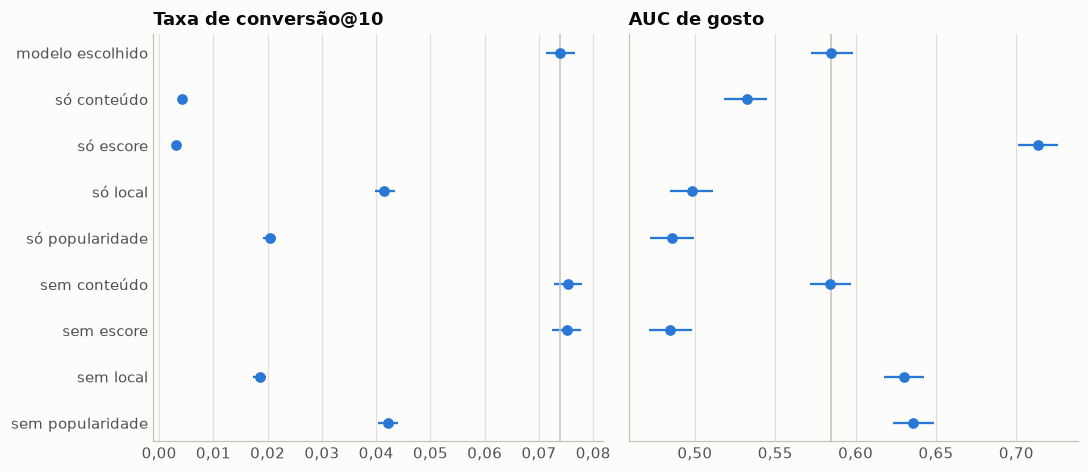

In [12]:
def sem_componente(pesos, indice):
    restantes = [0.0 if i == indice else peso for i, peso in enumerate(pesos)]
    soma = sum(restantes)
    return tuple(peso / soma for peso in restantes)


nomes_componentes = ["conteúdo", "escore", "local", "popularidade"]
casos_ablacao = {"modelo escolhido": pesos_finais}
for i, nome in enumerate(nomes_componentes):
    casos_ablacao[f"só {nome}"] = tuple(1.0 if j == i else 0.0 for j in range(4))
for i, nome in enumerate(nomes_componentes):
    if pesos_finais[i] > 0:
        casos_ablacao[f"sem {nome}"] = sem_componente(pesos_finais, i)
resultados_ablacao = {nome: medir(componentes_atuais, pesos) for nome, pesos in casos_ablacao.items()}
display(tabela_contra_base(resultados_ablacao, "modelo escolhido"))

nomes_casos = list(resultados_ablacao)[::-1]
figura, (eixo_conversao, eixo_gosto) = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for eixo, metrica, titulo, casas in [(eixo_conversao, "conversao", "Taxa de conversão@10", 2), (eixo_gosto, "auc_gosto", "AUC de gosto", 2)]:
    medias, inferiores, superiores = zip(*(intervalo(resultados_ablacao[nome], metrica) for nome in nomes_casos))
    medias, inferiores, superiores = np.array(medias), np.array(inferiores), np.array(superiores)
    eixo.errorbar(medias, range(len(nomes_casos)), xerr=[medias - inferiores, superiores - medias], fmt="o", color=COR_PRINCIPAL, markersize=6, capsize=0, elinewidth=1.5)
    eixo.axvline(medias[nomes_casos.index("modelo escolhido")], color=COR_EIXO, linewidth=1)
    eixo.set_title(titulo)
    eixo.grid(axis="y", visible=False)
    eixo_br(eixo.xaxis, casas)
eixo_conversao.set_yticks(range(len(nomes_casos)), nomes_casos)
figura.tight_layout()
salvar(figura, "32_ablacao")
plt.show()

**Ablação:**

- **Local e popularidade respondem pela conversão:** sem local, ela cai para 0,0185; sem popularidade, para 0,0421.
- **O escore responde pelo gosto:** sem ele, a AUC de gosto cai para 0,4847, um valor abaixo de 0,5; sozinho, chega a 0,7136, mas cobre só 1,0% do catálogo e converte 0,0031.
- **A combinação vale mais que as partes:** nenhum componente sozinho passa de 0,0415 de conversão, contra 0,0739 do modelo.
- **O conteúdo não melhora as métricas principais no cenário 1:** sem ele, a conversão é até maior (0,0015, IC 95% de 0,0005 a 0,0024) e a AUC de gosto empata (−0,0007, IC 95% de −0,0061 a 0,0046). A contribuição dele é ampliar o catálogo (45,9% × 40,8%), e o peso de 0,1 é o mínimo exigido. O papel principal do conteúdo está no cenário 3, a ser medido na seção 3.6.

### Sensibilidade

Outros limiares do critério, e usuários com ao menos uma avaliação no treino, em vez de três. Nesse segundo caso, avaliam-se só as combinações que passaram de 90% da melhor conversão na grade principal.

,limiar,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
0,0.90,0.1,0.3,0.4,0.2,0.0696,0.0774,0.6144,0.4073
1,0.95,0.1,0.2,0.5,0.2,0.0739,0.0836,0.5850,0.4595
2,0.97,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004


Fronteira com a configuração final:


,limiar de conversão,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo,conversão cedida,gosto ganho
0,1.00,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004,0.0000,0.0000
1,0.97,0.1,0.1,0.6,0.2,0.0767,0.0891,0.5431,0.5004,0.0000,0.0000
2,0.95,0.1,0.2,0.5,0.2,0.0739,0.0836,0.5850,0.4595,0.0358,0.0418
3,0.90,0.1,0.3,0.4,0.2,0.0696,0.0774,0.6144,0.4073,0.0927,0.0713
4,0.85,0.2,0.3,0.3,0.2,0.0667,0.0742,0.6167,0.4623,0.1300,0.0735
5,0.80,0.1,0.4,0.3,0.2,0.0644,0.0709,0.6411,0.3256,0.1605,0.0980
6,0.70,0.1,0.5,0.3,0.1,0.0538,0.0588,0.6677,0.3538,0.2983,0.1246


Correlação entre conversão e AUC de gosto na grade final: -0,36


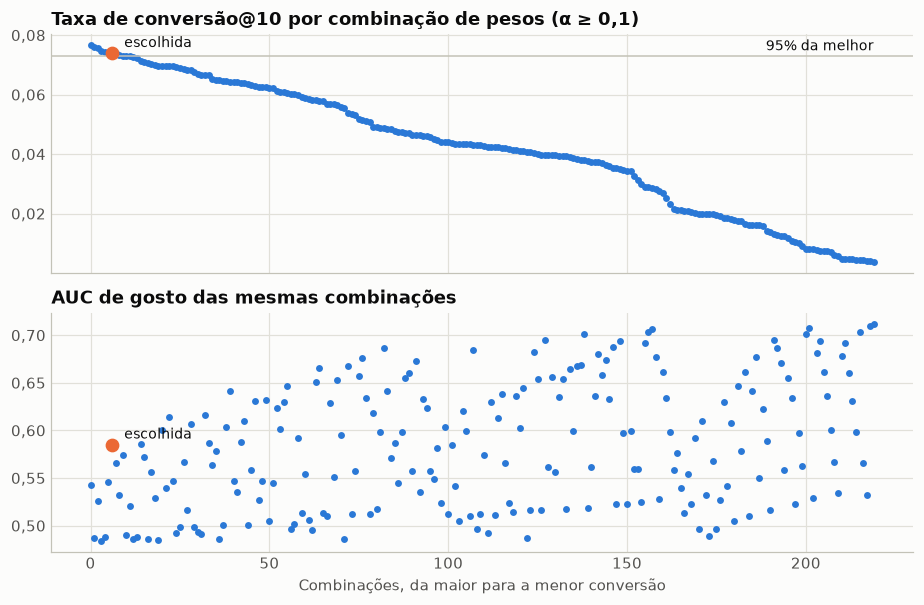

Usuários com 1 ou mais avaliações: 10.000; combinações avaliadas: 25
Escolhida nesse grupo: (0.1, 0.2, 0.5, 0.2), conversão 0,0598, AUC de gosto 0,5783
Pesos do cenário 1 nesse grupo: conversão 0,0598, AUC de gosto 0,5783


In [13]:
grade_final = grade if not mudou_etapa3 else avaliar_grade("etapa2_pesos_final", protocolo_antigo, componentes_atuais, grade_de_pesos(0.1), configuracao)
linhas_limiar = []
for limiar in [0.90, 0.95, 0.97]:
    combinacao = escolher_pesos(grade_final, limiar=limiar)
    linhas_limiar.append({"limiar": limiar} | combinacao[colunas_grade].astype(float).to_dict())
display(pd.DataFrame(linhas_limiar).round(4))

elegiveis_grade_final = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
melhor_final = elegiveis_grade_final.sort_values("conversao", ascending=False).iloc[0]
fronteira_final = pd.DataFrame(
    [{"limiar de conversão": limiar} | escolher_pesos(grade_final, limiar=limiar)[colunas_grade].astype(float).to_dict() for limiar in limiares_fronteira]
)
fronteira_final["conversão cedida"] = 1 - fronteira_final["conversao"] / melhor_final["conversao"]
fronteira_final["gosto ganho"] = fronteira_final["auc_gosto"] - melhor_final["auc_gosto"]
print("Fronteira com a configuração final:")
display(fronteira_final.round(4))
print(f"Correlação entre conversão e AUC de gosto na grade final: {numero_br(elegiveis_grade_final['conversao'].corr(elegiveis_grade_final['auc_gosto']), 2)}")

ordenada = elegiveis_grade_final.sort_values("conversao", ascending=False).reset_index(drop=True)
posicao_escolhida = ordenada.index[(ordenada[NOMES_PESOS].sub(list(pesos_finais)).abs().sum(axis=1) < 1e-9)][0]
figura, (eixo_conversao, eixo_gosto) = plt.subplots(2, 1, figsize=(8.5, 5.6), sharex=True)
eixo_conversao.plot(ordenada.index, ordenada["conversao"], "o", color=COR_PRINCIPAL, markersize=3.5)
eixo_conversao.axhline(0.95 * ordenada["conversao"].max(), color=COR_EIXO, linewidth=1)
eixo_conversao.annotate("95% da melhor", (len(ordenada) - 1, 0.95 * ordenada["conversao"].max()), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=9)
eixo_conversao.plot(posicao_escolhida, ordenada.loc[posicao_escolhida, "conversao"], "o", color=COR_SECUNDARIA, markersize=8)
eixo_conversao.annotate("escolhida", (posicao_escolhida, ordenada.loc[posicao_escolhida, "conversao"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
eixo_conversao.set_title("Taxa de conversão@10 por combinação de pesos (α ≥ 0,1)")
eixo_br(eixo_conversao.yaxis, 2)
eixo_gosto.plot(ordenada.index, ordenada["auc_gosto"], "o", color=COR_PRINCIPAL, markersize=3.5)
eixo_gosto.plot(posicao_escolhida, ordenada.loc[posicao_escolhida, "auc_gosto"], "o", color=COR_SECUNDARIA, markersize=8)
eixo_gosto.annotate("escolhida", (posicao_escolhida, ordenada.loc[posicao_escolhida, "auc_gosto"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
eixo_gosto.set_title("AUC de gosto das mesmas combinações")
eixo_gosto.set_xlabel("Combinações, da maior para a menor conversão")
eixo_br(eixo_gosto.yaxis, 2)
figura.tight_layout()
salvar(figura, "31_grade_pesos")
plt.show()


protocolo_amplo = montar_protocolo(treino, validacao, locais, ["antigo", "intermediario"])
componentes_amplos = calcular_componentes(treino, locais, protocolo_amplo.usuarios, protocolo_amplo.candidatos, **configuracao)
elegiveis_final = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
finalistas_amplos = elegiveis_final[elegiveis_final["conversao"] >= 0.9 * elegiveis_final["conversao"].max()]
combinacoes_amplas = [tuple(float(linha[nome]) for nome in NOMES_PESOS) for _, linha in finalistas_amplos.iterrows()]
grade_ampla = avaliar_grade("sensibilidade_um_ou_mais", protocolo_amplo, componentes_amplos, combinacoes_amplas, configuracao)
print(f"Usuários com 1 ou mais avaliações: {inteiro(len(protocolo_amplo.usuarios))}; combinações avaliadas: {len(grade_ampla)}")
escolha_ampla = escolher_pesos(grade_ampla)
print(f"Escolhida nesse grupo: {tuple(float(escolha_ampla[nome]) for nome in NOMES_PESOS)}, conversão {numero_br(escolha_ampla['conversao'], 4)}, AUC de gosto {numero_br(escolha_ampla['auc_gosto'], 4)}")
linha_final = grade_ampla[grade_ampla[NOMES_PESOS].sub(list(pesos_finais)).abs().sum(axis=1) < 1e-9]
if len(linha_final):
    print(f"Pesos do cenário 1 nesse grupo: conversão {numero_br(linha_final['conversao'].iloc[0], 4)}, AUC de gosto {numero_br(linha_final['auc_gosto'].iloc[0], 4)}")

**Sensibilidade:** com limiar de 90%, os pesos mudam para 0,1 / 0,3 / 0,4 / 0,2 (conversão de 0,0696 e AUC de 0,6144); com 97%, para 0,1 / 0,1 / 0,6 / 0,2 (0,0767 e 0,5431). A escolha depende do limiar, porque conversão e gosto competem (correlação de −0,36 na grade final): cada ganho de gosto custa conversão. Ceder 3,6% da melhor conversão rende 0,0418 de AUC de gosto, e ceder 9,3% rende 0,0713. Com usuários de 1 ou mais avaliações, a amostra de 10.000 escolhe os mesmos pesos (conversão de 0,0598 e AUC de 0,5783), o que indica estabilidade.

### Finalistas

A correlação de rankings é lenta, então só os finalistas a recebem, junto com as demais métricas. Aqui a lista óbvia da serendipidade é popularidade + local, em partes iguais.

In [14]:
elegiveis_f = grade_final[grade_final["alfa"] >= 0.1 - 1e-9]
aptas_f = elegiveis_f[elegiveis_f["conversao"] >= 0.95 * elegiveis_f["conversao"].max()].sort_values("auc_gosto", ascending=False).head(4)
finalistas = {f"{tuple(float(linha[n]) for n in NOMES_PESOS)}": tuple(float(linha[n]) for n in NOMES_PESOS) for _, linha in aptas_f.iterrows()}
modelo_obvio = modelo_ponderado(componentes_atuais, (0.0, 0.0, 0.5, 0.5))
vetorizador_final = VetorizadorConteudo(**configuracao.get("opcoes_vetor", {})).fit(locais[locais["gmap_id"].isin(treino["gmap_id"])])
vetores_finais = vetorizador_final.transform(locais.iloc[indice_locais.loc[protocolo_antigo.candidatos]])
tabela_finalistas = pd.DataFrame(
    {
        nome: medir(componentes_atuais, pesos, completo=True, com_correlacao=True, vetores=vetores_finais, modelo_obvio=modelo_obvio).resumo()
        for nome, pesos in finalistas.items()
    }
).round(4)
tabela_finalistas

,"(0.1, 0.2, 0.5, 0.2)","(0.1, 0.1, 0.7, 0.1)","(0.1, 0.2, 0.4, 0.3)","(0.2, 0.1, 0.5, 0.2)"
conversao,0.0739,0.0731,0.0739,0.0741
consumo,0.0836,0.0835,0.0843,0.0861
auc_gosto,0.5850,0.5745,0.5661,0.5458
spearman,0.1200,0.1044,0.0892,0.0663
kendall,0.1024,0.0896,0.0763,0.0561
auc_consumo,0.9167,0.9084,0.9211,0.9163
novidade,9.0859,9.3147,8.8585,9.0752
diversidade,0.6916,0.6939,0.6853,0.6760
serendipidade,0.0236,0.0267,0.0185,0.0234
cobertura_catalogo,0.4595,0.6272,0.3707,0.6018


**Finalistas:** a correlação de rankings confirma a AUC de gosto: a combinação escolhida tem os maiores Spearman (0,1200) e tau-b de Kendall (0,1024). Esses valores são baixos, o que confirma o pouco espaço para prever o gosto. A AUC de consumo fica entre 0,91 e 0,92 em todas, então ela não separa os finalistas, como esperado. Serendipidade, novidade e diversidade variam pouco e servem só de acompanhamento.

## Implementação do recomendador

A classe `Recomendador` reúne os componentes e a configuração congelada. Ela recomenda para usuário com histórico, inclusive com 1 ou 2 avaliações, para usuário novo e para local novo. Os pesos dos cenários 2 e 3 são decididos nas seções seguintes, e a classe já os usa por padrão. Nomes de pessoas não aparecem: os exemplos usam "Usuário A".

In [15]:
recomendador = Recomendador(
    pesos=pesos_finais,
    percentil=configuracao["percentil"],
    centro=configuracao["centro"],
    local=configuracao["local"],
    tau=configuracao.get("tau"),
    opcoes_vetor=configuracao.get("opcoes_vetor"),
).ajustar(treino, locais)

amostra_conferencia = protocolo_antigo.usuarios[:200]
pontuacoes_classe = recomendador.pontuar(amostra_conferencia, protocolo_antigo.candidatos)
pontuacoes_etapa = pontuar_componentes(componentes_atuais, pesos_finais)[:200]
print(f"Mesmas pontuações da etapa anterior: {bool(np.allclose(pontuacoes_classe, pontuacoes_etapa))}")

sem_traducao = [nome for nome in recomendador.nomes_tokens if traduzir_token(nome) is None]
print(f"Tokens no vetor: {len(recomendador.nomes_tokens)}; sem tradução: {len(sem_traducao)}")

gerador_exemplo = np.random.default_rng(42)
ativos_exemplo = recomendador.avaliacoes_por_usuario[recomendador.avaliacoes_por_usuario >= 5].index.intersection(protocolo_antigo.usuarios)
usuario_a = gerador_exemplo.choice(np.sort(ativos_exemplo.to_numpy().astype(str)))
inicio = perf_counter()
lista_a = recomendador.recomendar(usuario_a, n=10)
print(f"Tempo de uma lista com explicações: {numero_br(perf_counter() - inicio, 2)} s")

historico_a = treino[treino["user_id"] == usuario_a].merge(locais[["gmap_id", "name", "cidade", "categoria_principal"]], on="gmap_id")
print(f"Usuário A: {len(historico_a)} avaliações no treino")
display(historico_a.sort_values("rating", ascending=False)[["name", "cidade", "categoria_principal", "rating"]].head(8).reset_index(drop=True))
with pd.option_context("display.max_colwidth", 110):
    display(lista_a[["nome", "cidade", "categoria_principal", "pontuacao"]].round(3))
    display(lista_a[["nome", "explicacao"]].head(5))

Mesmas pontuações da etapa anterior: True
Tokens no vetor: 167; sem tradução: 0


Tempo de uma lista com explicações: 0,18 s
Usuário A: 5 avaliações no treino


,name,cidade,categoria_principal,rating
0,Pizza Hut,Cheyenne,Pizza delivery,5
1,R&B Breakfast Club,Cheyenne,Breakfast restaurant,5
2,Applebee's Grill + Bar,Cheyenne,Restaurant,5
3,Chili's Grill & Bar,Cheyenne,Tex-Mex restaurant,5
4,Guadalajara Mexican Restaurant Cheyenne,Cheyenne,Mexican restaurant,4


,nome,cidade,categoria_principal,pontuacao
0,Texas Roadhouse,Cheyenne,Steak house,0.919
1,Chick-fil-A,Cheyenne,Fast food restaurant,0.915
2,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.906
3,2 Doors Down,Cheyenne,American restaurant,0.903
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.901
5,Wasabi,Cheyenne,Sushi restaurant,0.894
6,Culver's,Cheyenne,American restaurant,0.888
7,Anong's | Thai Cuisine,Cheyenne,Thai restaurant,0.881
8,Paramount Cafe,Cheyenne,Coffee shop,0.880
9,Rodolfo's Mexican Grill,Cheyenne,Restaurant,0.847


,nome,explicacao
0,Texas Roadhouse,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Restaurante americano, Chu..."
1,Chick-fil-A,"Porque você gostou de R&B Breakfast Club (nota 5). Em comum com seu perfil: Café da manhã, Restaurante fam..."
2,"Wyoming's Rib & Chop House, Cheyenne","Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Churrascaria, Restaurante ..."
3,2 Doors Down,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar no local, Hamburgueria..."
4,Sanford's Grub & Pub,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar e grill, Refeição no l..."


In [16]:
amostra_explicacoes = gerador_exemplo.choice(protocolo_antigo.usuarios, size=100, replace=False)
com_parecido, quantidade_tokens, avaliados_na_lista, fechados_na_lista = [], [], 0, 0
fechados_ids = set(locais.loc[locais["fechado_perm"] | locais["fechado_temp"], "gmap_id"])
for usuario in amostra_explicacoes:
    lista = recomendador.recomendar(usuario, n=10, com_explicacao=False)
    avaliados_usuario = set(treino.loc[treino["user_id"] == usuario, "gmap_id"])
    avaliados_na_lista += len(set(lista["gmap_id"]) & avaliados_usuario)
    fechados_na_lista += len(set(lista["gmap_id"]) & fechados_ids)
    for gmap_id in lista["gmap_id"]:
        explicacao = recomendador.explicar(usuario, gmap_id)
        com_parecido.append(explicacao["parecido"] is not None)
        quantidade_tokens.append(len(explicacao["tokens"]))
print(f"Em 100 usuários e 1.000 recomendações:")
print(f"  com local parecido na explicação: {numero_br(100 * np.mean(com_parecido), 1)}%")
print(f"  tokens por explicação: média {numero_br(np.mean(quantidade_tokens), 2)}")
print(f"  já avaliados na lista: {avaliados_na_lista}; fechados na lista: {fechados_na_lista}")

previsoes_a = recomendador.prever_nota([usuario_a] * 3, lista_a["gmap_id"].head(3).tolist())
print(f"Nota prevista para os 3 primeiros do Usuário A: {[numero_br(valor, 2) for valor in previsoes_a]}")

print("Usuário novo em Cheyenne, com café como preferência (pesos do cenário 2):")
display(recomendador.recomendar_usuario_novo(cidade="Cheyenne", categorias=["Coffee shop"], n=5)[["nome", "cidade", "categoria_principal", "pontuacao"]].round(3))

novos_naturais = pd.read_parquet(PASTA_CONJUNTOS / "locais_novos.parquet").query("origem == 'natural' and conjunto == 'validacao'")
cadastro_real = locais[locais["gmap_id"].isin(novos_naturais["gmap_id"]) & ~locais["fechado_perm"] & ~locais["fechado_temp"]].iloc[0].to_dict()
print(f"Local novo real: {cadastro_real['name']} ({cadastro_real['cidade']}, {cadastro_real['categoria_principal']}), tratado como cadastro (pesos do cenário 3)")
print(recomendador.posicao_local_novo(usuario_a, cadastro_real, n=10))
inicio = perf_counter()
tabela_novos = recomendador.usuarios_para_local_novo(cadastro_real, n=5)
print(f"Tempo para ordenar os usuários antigos: {numero_br(perf_counter() - inicio, 2)} s")
tabela_novos.drop(columns="user_id").assign(usuario=[f"Usuário #{i + 1}" for i in range(len(tabela_novos))]).round(3)

Em 100 usuários e 1.000 recomendações:
  com local parecido na explicação: 99,0%
  tokens por explicação: média 2,83
  já avaliados na lista: 0; fechados na lista: 0
Nota prevista para os 3 primeiros do Usuário A: ['4,70', '4,83', '4,61']
Usuário novo em Cheyenne, com café como preferência (pesos do cenário 2):


,nome,cidade,categoria_principal,pontuacao
0,Texas Roadhouse,Cheyenne,Steak house,0.943
1,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.939
2,Chick-fil-A,Cheyenne,Fast food restaurant,0.936
3,2 Doors Down,Cheyenne,American restaurant,0.928
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.922


Local novo real: Jackson Lake Lodge Pool Dining and BBQ (Moran, Family restaurant), tratado como cadastro (pesos do cenário 3)
{'posicao': 1342, 'total': 1415, 'recomendar': False, 'pontuacao': 0.31803617612416846}


Tempo para ordenar os usuários antigos: 0,24 s


,pontuacao,conteudo,local,usuario
0,0.848,0.842,0.853,Usuário #1
1,0.807,0.753,0.861,Usuário #2
2,0.804,0.793,0.815,Usuário #3
3,0.803,0.793,0.814,Usuário #4
4,0.798,0.803,0.792,Usuário #5


**Leitura:** a classe dá exatamente as mesmas pontuações da etapa anterior, os 167 tokens do vetor têm tradução, e uma lista com explicações leva 0,13 s. Em 100 usuários e 1.000 recomendações, nenhum local fechado ou já avaliado entrou na lista, e 99,0% das explicações têm um local parecido.

**Duas limitações visíveis nos exemplos:**

- **A lista é pouco pessoal:** o Usuário A, de Cheyenne, recebe sobretudo os locais populares e bem avaliados da cidade dele. Isso é coerente com a ablação: local e popularidade respondem pela conversão, e o conteúdo tem peso de 0,1.
- **A explicação é uma justificativa, não a causa:** "porque você gostou de X" aponta o local mais parecido, mas o que mais pesa na posição é o local e a popularidade. Por isso, a interface mostra também as barras dos componentes, como o plano prevê.

Na lista do usuário novo, a preferência por café quase não muda o resultado, como a seção do cenário 2 mostra para todos os casos. Um local novo real em Moran ficou em 1.342º de 1.415 para um usuário de Cheyenne, o que é coerente com a distância; a seção do cenário 3 mede isso em todos os casos. Com a cota de novidade do cenário 3, a lista do Usuário A termina com um local novo, o Rodolfo's Mexican Grill, no lugar do 10º colocado.

### Escore bayesiano e exemplos: Usuário A e Usuário B

A figura mostra o escore congelado (`m` no percentil 25) contra a média simples. Depois, dois usuários reais do protocolo do cenário 1, anonimizados, com o histórico no treino, os tokens que mais pesam no perfil e o top-10 explicado. O Usuário B é sorteado entre os antigos com 5 ou mais avaliações cuja cidade mais avaliada não é a do Usuário A.

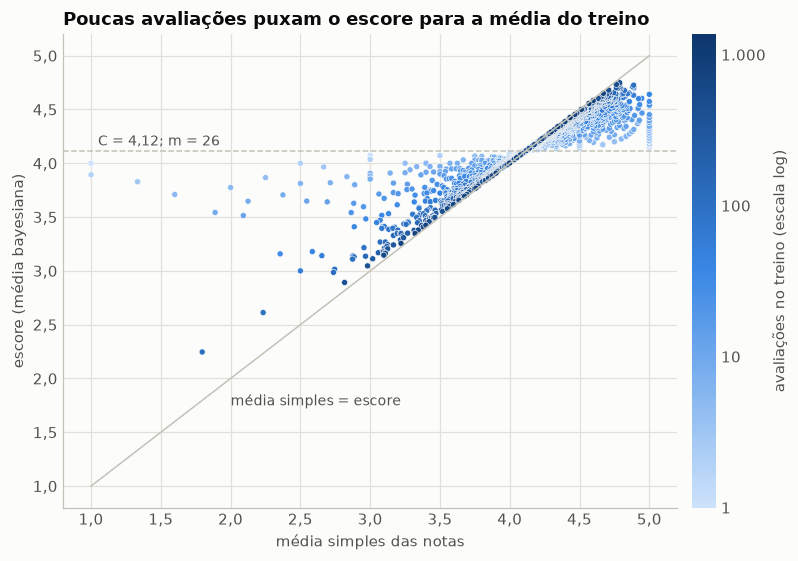

Locais avaliados no treino: 1.647; com menos de 10 avaliações: 194, cuja média simples vai de 1,00 a 5,00 e o escore, de 3,54 a 4,34


In [17]:
escores_finais = recomendador.escores
avaliados_finais = escores_finais[escores_finais["avaliacoes"] > 0]
C_final, m_final = recomendador.parametros["C"], recomendador.parametros["m"]
figura, eixo = plt.subplots(figsize=(7.5, 5.2))
ordem_figura = avaliados_finais.sort_values("avaliacoes")
pontos = eixo.scatter(
    ordem_figura["media"], ordem_figura["escore"], c=ordem_figura["avaliacoes"], cmap=ESCALA_SEQUENCIAL,
    norm=LogNorm(vmin=1, vmax=ordem_figura["avaliacoes"].max()), s=16, linewidths=0.4, edgecolors=COR_FUNDO,
)
eixo.plot([1, 5], [1, 5], color=COR_EIXO, linewidth=1)
eixo.axhline(C_final, color=COR_EIXO, linewidth=1, linestyle="--")
eixo.annotate(f"C = {numero_br(C_final, 2)}; m = {numero_br(m_final)}", (1.05, C_final + 0.05), color=COR_TEXTO_SECUNDARIO, fontsize=9)
eixo.annotate("média simples = escore", (2.0, 1.75), color=COR_TEXTO_SECUNDARIO, fontsize=9)
barra = figura.colorbar(pontos, ax=eixo, pad=0.02)
barra.set_label("avaliações no treino (escala log)")
barra.outline.set_visible(False)
barra.set_ticks([1, 10, 100, 1000], labels=["1", "10", "100", "1.000"])
barra.minorticks_off()
eixo.set_xlabel("média simples das notas")
eixo.set_ylabel("escore (média bayesiana)")
eixo.set_title("Poucas avaliações puxam o escore para a média do treino")
eixo_br(eixo.xaxis, 1)
eixo_br(eixo.yaxis, 1)
figura.tight_layout()
salvar(figura, "30_escore_bayesiano")
plt.show()
poucos = avaliados_finais[avaliados_finais["avaliacoes"] < 10]
print(f"Locais avaliados no treino: {inteiro(len(avaliados_finais))}; com menos de 10 avaliações: {inteiro(len(poucos))}, "
      f"cuja média simples vai de {numero_br(poucos['media'].min(), 2)} a {numero_br(poucos['media'].max(), 2)} e o escore, de {numero_br(poucos['escore'].min(), 2)} a {numero_br(poucos['escore'].max(), 2)}")

In [18]:
def tokens_do_perfil(usuario, quantidade=6):
    vetor = recomendador.perfis[recomendador._linha_perfil[usuario]].toarray().ravel()
    ordem = np.argsort(-vetor)
    traduzidos = [(traduzir_token(recomendador.nomes_tokens[j]), vetor[j]) for j in ordem if vetor[j] > 0]
    return [f"{nome} ({numero_br(peso, 2)})" for nome, peso in traduzidos if nome is not None][:quantidade]


cidade_dos_locais = locais.set_index("gmap_id")["cidade"]
treino_ativos = treino[treino["user_id"].isin(ativos_exemplo)]
cidade_principal = treino_ativos.assign(cidade=treino_ativos["gmap_id"].map(cidade_dos_locais)).groupby("user_id")["cidade"].agg(lambda c: c.mode().iloc[0] if c.notna().any() else None)
cidade_a = cidade_principal[usuario_a]
elegiveis_b = np.sort([u for u in ativos_exemplo.to_numpy().astype(str) if cidade_principal.get(u) not in (cidade_a, None)])
usuario_b_antigo = np.random.default_rng(42).choice(elegiveis_b)

for rotulo, usuario in [("Usuário A", usuario_a), ("Usuário B", usuario_b_antigo)]:
    historico = treino[treino["user_id"] == usuario].merge(locais[["gmap_id", "name", "cidade", "categoria_principal"]], on="gmap_id")
    print(f"{rotulo}: {len(historico)} avaliações no treino, cidade mais avaliada {cidade_principal[usuario]}")
    print(f"  Tokens do perfil (cenário 1): {', '.join(tokens_do_perfil(usuario))}")
    display(historico.sort_values("rating", ascending=False)[["name", "cidade", "categoria_principal", "rating"]].head(6).reset_index(drop=True))
    lista = recomendador.recomendar(usuario, n=10)
    with pd.option_context("display.max_colwidth", 120):
        display(lista[["nome", "cidade", "categoria_principal", "pontuacao", "novo", "explicacao"]].round(3))

Usuário A: 5 avaliações no treino, cidade mais avaliada Cheyenne
  Tokens do perfil (cenário 1): Bar no local (0,20), Restaurante (0,18), Café da manhã (0,17), Hamburgueria (0,15), Bar e grill (0,14), Restaurante americano (0,11)


,name,cidade,categoria_principal,rating
0,Pizza Hut,Cheyenne,Pizza delivery,5
1,R&B Breakfast Club,Cheyenne,Breakfast restaurant,5
2,Applebee's Grill + Bar,Cheyenne,Restaurant,5
3,Chili's Grill & Bar,Cheyenne,Tex-Mex restaurant,5
4,Guadalajara Mexican Restaurant Cheyenne,Cheyenne,Mexican restaurant,4


,nome,cidade,categoria_principal,pontuacao,novo,explicacao
0,Texas Roadhouse,Cheyenne,Steak house,0.919,False,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Restaurante americano, Churrascaria,..."
1,Chick-fil-A,Cheyenne,Fast food restaurant,0.915,False,"Porque você gostou de R&B Breakfast Club (nota 5). Em comum com seu perfil: Café da manhã, Restaurante familiar, Ref..."
2,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.906,False,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Churrascaria, Restaurante familiar, ..."
3,2 Doors Down,Cheyenne,American restaurant,0.903,False,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar no local, Hamburgueria, Restaura..."
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.901,False,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Bar e grill, Refeição no local, Para..."
5,Wasabi,Cheyenne,Sushi restaurant,0.894,False,"Porque você gostou de Chili's Grill & Bar (nota 5). Em comum com seu perfil: Bar no local, Refeição no local, Para v..."
6,Culver's,Cheyenne,American restaurant,0.888,False,"Porque você gostou de Applebee's Grill + Bar (nota 5). Em comum com seu perfil: Hamburgueria, Restaurante, Restauran..."
7,Anong's | Thai Cuisine,Cheyenne,Thai restaurant,0.881,False,"Porque você gostou de R&B Breakfast Club (nota 5). Em comum com seu perfil: Restaurante, Refeição no local, Para via..."
8,Paramount Cafe,Cheyenne,Coffee shop,0.880,False,"Porque você gostou de Guadalajara Mexican Restaurant Cheyenne (nota 4). Em comum com seu perfil: Refeição no local, ..."
9,Rodolfo's Mexican Grill,Cheyenne,Restaurant,0.847,True,"Porque você gostou de R&B Breakfast Club (nota 5). Em comum com seu perfil: Restaurante, Para viagem, Entrada acessí..."


Usuário B: 23 avaliações no treino, cidade mais avaliada Evanston


  Tokens do perfil (cenário 1): Restaurante (0,27), Fast food (0,22), Pagamento por aproximação (0,21), Restaurante americano (0,19), Restaurante mexicano (0,19), Drive-thru (0,15)


,name,cidade,categoria_principal,rating
0,Wonderful Inn,Evanston,Chinese restaurant,5
1,Jilly Beanz,Evanston,Fast food restaurant,5
2,The Krave,Evanston,Ice cream shop,5
3,Daylight Donuts,Evanston,Donut shop,5
4,Painted Lady,Evanston,Bar & grill,5
5,Ana's On Main St.,Evanston,Coffee shop,5


,nome,cidade,categoria_principal,pontuacao,novo,explicacao
0,Jalisco Mexican Grill,Evanston,Mexican restaurant,0.851,False,"Porque você gostou de Don Pedro's Family Mexican Restaurant (nota 5). Em comum com seu perfil: Restaurante mexicano,..."
1,Jimmy John's,Evanston,Sandwich shop,0.830,False,"Porque você gostou de Arby's (nota 5). Em comum com seu perfil: Fast food, Pagamento por aproximação, Drive-thru."
2,Kate's,Evanston,Bar,0.820,False,Porque você gostou de Tumblin Tumbleweeds Restaurant (nota 5). Em comum com seu perfil: Entrega.
3,La Cocina De Marivel,Evanston,Restaurant,0.818,True,"Porque você gostou de Mother Mae's Kitchen (nota 5). Em comum com seu perfil: Restaurante, Aceita reservas, Aceita c..."
4,Taco Bell,Evanston,Fast food restaurant,0.817,False,"Porque você gostou de McDonald's (nota 5). Em comum com seu perfil: Pagamento por aproximação, Drive-thru, Restauran..."
5,Paff's,Evanston,Fast food restaurant,0.815,True,"Porque você gostou de Jilly Beanz (nota 5). Em comum com seu perfil: Fast food, Aceita cartão de crédito, Entrega."
6,Munchies Ice Cream and snack shack,Evanston,Ice cream shop,0.814,True,"Porque você gostou de The Krave (nota 5). Em comum com seu perfil: Sorveteria, Entrega, Para viagem."
7,Misk'i,Evanston,Peruvian restaurant,0.814,True,"Porque você gostou de The Krave (nota 5). Em comum com seu perfil: Sorveteria, Pagamento por aproximação, Aceita res..."
8,Papa Murphy's | Take 'N' Bake Pizza,Evanston,Pizza restaurant,0.812,False,"Porque você gostou de Arby's (nota 5). Em comum com seu perfil: Pagamento por aproximação, Entrega, Aceita cheques."
9,Pizza Hut,Evanston,Pizza delivery,0.809,False,"Porque você gostou de Costa Vida (nota 5). Em comum com seu perfil: Banheiro acessível, Entrega, Restaurante para vi..."


**Leitura:** com `m` = 26, os 194 locais com menos de 10 avaliações no treino têm média simples de 1 a 5, mas escore só de 3,54 a 4,34, perto de `C`; os locais com centenas de avaliações ficam sobre a diagonal. O Usuário A, de Cheyenne, tem um perfil de bar, restaurante, café da manhã e hamburgueria, e a lista dele termina com um local novo, pela cota. O Usuário B, de Evanston, tem um perfil de restaurante, fast food e restaurante mexicano; a lista começa com um restaurante mexicano explicado por outro que ele avaliou com nota 5, e quatro locais novos entram por mérito, sem a cota.

## Cenário 2: usuário novo

**Protocolo:** usuários `novo` na validação (sem avaliações no treino) com 2 ou mais avaliações no período. Em ordem de data, a **primeira** simula o cadastro e as demais são o alvo. O cadastro informa a cidade do local avaliado e, conforme o método, a categoria principal dele (o que a pessoa marcaria num formulário) ou o próprio local, como exemplo. Esse local sai da lista e do alvo. Valem as regras do protocolo único: candidatos abertos do treino, até 10.000 usuários com ao menos uma conversão, desempate por sorteio.

**Métodos comparados:**

1. popularidade global;
2. escore global;
3. escore + popularidade, sem informação alguma;
4. local declarado + escore + popularidade;
5. o 4 + categorias declaradas, com peso 0,05, 0,1 e 0,2, e também como filtro (os locais da categoria vêm primeiro e os demais completam a lista);
6. o 4 + o local de exemplo, por similaridade de conteúdo, com peso 0,05, 0,1 e 0,2.

Os pesos dos métodos 3 e 4 vêm de uma grade com passo de 0,1, pelo mesmo critério do cenário 1, sem exigir conteúdo. Nos métodos 5 e 6, o conteúdo entra com peso `α` e os demais pesos do método 4 são multiplicados por `1 − α`. O local declarado é a proximidade ao centro da cidade informada, `exp(−km / τ)` com o mesmo τ = 200 km do cenário 1.

In [19]:
cadastros_validacao, pares_cadastro = simular_cadastros(validacao, locais)
alvo_novo = validacao[validacao["user_id"].isin(cadastros_validacao.index)]
protocolo_novo = montar_protocolo(treino, alvo_novo, locais, ["novo"], pares_excluidos=pares_cadastro)
cadastros_novo = cadastros_validacao.loc[protocolo_novo.usuarios]
assert np.array_equal(protocolo_novo.candidatos, protocolo_antigo.candidatos)

usuarios_novos = validacao.loc[validacao["segmento"] == "novo", "user_id"]
print(f"Usuários novos na validação: {inteiro(usuarios_novos.nunique())}")
print(f"Com 2 ou mais avaliações: {inteiro(len(cadastros_validacao))}")
print(f"No protocolo (ao menos uma conversão depois do cadastro): {inteiro(len(protocolo_novo.usuarios))}")
print(f"Avaliações no alvo, sem o cadastro: {inteiro(protocolo_novo.notas.nnz)}")
print(f"Cadastros sem cidade: {inteiro(cadastros_novo['cidade'].map(lambda valor: not isinstance(valor, str)).sum())}")
local_exemplo_no_treino = cadastros_novo["local_exemplo"].isin(treino["gmap_id"])
print(f"Local de exemplo que é um local novo (fora do treino): {numero_br(100 * (1 - local_exemplo_no_treino.mean()), 1)}%")
cidade_dos_candidatos = locais.set_index("gmap_id")["cidade"].reindex(protocolo_novo.candidatos).to_numpy()
mesma_cidade = [
    (cidade_dos_candidatos[protocolo_novo.notas[i].indices] == cidade).mean()
    for i, cidade in enumerate(cadastros_novo["cidade"])
]
print(f"Fração do alvo na cidade do cadastro (média por usuário): {numero_br(100 * np.mean(mesma_cidade), 1)}%")

so_cidade = cadastros_novo[["cidade"]]
componentes_novo = {
    "sem informação": recomendador.componentes_cadastros(cadastros_novo[[]], protocolo_novo.candidatos),
    "cidade": recomendador.componentes_cadastros(so_cidade, protocolo_novo.candidatos),
    "categorias": recomendador.componentes_cadastros(cadastros_novo[["cidade", "categorias"]], protocolo_novo.candidatos),
    "exemplo": recomendador.componentes_cadastros(cadastros_novo[["cidade", "local_exemplo"]], protocolo_novo.candidatos),
}
coincide_novo = recomendador.coincidencia_de_categorias(cadastros_novo, protocolo_novo.candidatos)
print(f"Candidatos da categoria declarada, por usuário (mediana): {inteiro(int(np.median(coincide_novo.sum(axis=1))))}")
na_categoria = [coincide_novo[i, protocolo_novo.notas[i].indices].mean() for i in range(len(protocolo_novo.usuarios))]
print(
    f"Fração do alvo na categoria declarada (média por usuário): {numero_br(100 * np.mean(na_categoria), 1)}%; "
    f"entre todos os candidatos: {numero_br(100 * coincide_novo.mean(), 1)}%"
)

Usuários novos na validação: 45.530
Com 2 ou mais avaliações: 12.037
No protocolo (ao menos uma conversão depois do cadastro): 10.000
Avaliações no alvo, sem o cadastro: 28.428
Cadastros sem cidade: 2


Local de exemplo que é um local novo (fora do treino): 2,3%


Fração do alvo na cidade do cadastro (média por usuário): 55,6%


Candidatos da categoria declarada, por usuário (mediana): 135


Fração do alvo na categoria declarada (média por usuário): 18,8%; entre todos os candidatos: 12,1%


In [20]:
def medir_novo(componentes, pesos, extra=None, **opcoes):
    def modelo(usuarios, candidatos):
        pontuacoes = pontuar_componentes(componentes, pesos)
        return pontuacoes if extra is None else pontuacoes + extra

    return avaliar(protocolo_novo, modelo, **opcoes)


def escolher_na_grade(nome, componentes, combinacoes):
    grade_metodo = avaliar_grade(nome, protocolo_novo, componentes, combinacoes, configuracao | {"cenario": 2, "metodo": nome})
    escolhida = escolher_pesos(grade_metodo, alfa_minimo=0)
    return tuple(float(escolhida[peso]) for peso in NOMES_PESOS), grade_metodo


grade_sem_alfa = [pesos for pesos in grade_de_pesos(0.1) if pesos[0] == 0]
pesos_metodo3, grade_metodo3 = escolher_na_grade("c2_escore_popularidade", componentes_novo["sem informação"], [p for p in grade_sem_alfa if p[2] == 0])
pesos_metodo4, grade_metodo4 = escolher_na_grade("c2_local_escore_popularidade", componentes_novo["cidade"], grade_sem_alfa)
print(f"Método 3, pesos (α, β, γ, δ): {pesos_metodo3}")
print(f"Método 4, pesos (α, β, γ, δ): {pesos_metodo4}")
colunas_grade_novo = NOMES_PESOS + ["conversao", "consumo", "auc_gosto", "cobertura_catalogo"]
print("Método 4, aptas com maior AUC de gosto:")
aptas_metodo4 = grade_metodo4[grade_metodo4["conversao"] >= 0.95 * grade_metodo4["conversao"].max()]
display(aptas_metodo4.sort_values("auc_gosto", ascending=False).head(6)[colunas_grade_novo].round(4))


def com_conteudo(pesos, alfa):
    return (alfa,) + tuple((1 - alfa) * peso for peso in pesos[1:])


metodos_novo = {
    "1. popularidade": (componentes_novo["sem informação"], (0.0, 0.0, 0.0, 1.0), None),
    "2. escore": (componentes_novo["sem informação"], (0.0, 1.0, 0.0, 0.0), None),
    "3. escore + popularidade": (componentes_novo["sem informação"], pesos_metodo3, None),
    "4. local + escore + popularidade": (componentes_novo["cidade"], pesos_metodo4, None),
}
for alfa in [0.05, 0.1, 0.2]:
    metodos_novo[f"5. + categorias, α = {numero_br(alfa, 2)}"] = (componentes_novo["categorias"], com_conteudo(pesos_metodo4, alfa), None)
metodos_novo["5. + categorias como filtro"] = (componentes_novo["cidade"], pesos_metodo4, coincide_novo)
for alfa in [0.05, 0.1, 0.2]:
    metodos_novo[f"6. + local de exemplo, α = {numero_br(alfa, 2)}"] = (componentes_novo["exemplo"], com_conteudo(pesos_metodo4, alfa), None)

modelo_obvio_novo = modelo_ponderado(componentes_novo["cidade"], (0.0, 0.0, 0.5, 0.5))
vetores_novo = recomendador.matriz[recomendador._posicao_local.reindex(protocolo_novo.candidatos).to_numpy()]
resultados_novo = {
    nome: medir_novo(componentes, pesos, extra, completo=True, vetores=vetores_novo, modelo_obvio=modelo_obvio_novo)
    for nome, (componentes, pesos, extra) in metodos_novo.items()
}
base_novo = "4. local + escore + popularidade"
display(tabela_contra_base(resultados_novo, base_novo))

Método 3, pesos (α, β, γ, δ): (0.0, 0.3, 0.0, 0.7)
Método 4, pesos (α, β, γ, δ): (0.0, 0.2, 0.5, 0.3)
Método 4, aptas com maior AUC de gosto:


,alfa,beta,gama,delta,conversao,consumo,auc_gosto,cobertura_catalogo
26,0.0,0.2,0.5,0.3,0.0484,0.0547,0.5539,0.2791
25,0.0,0.2,0.4,0.4,0.0487,0.0552,0.5457,0.2163
18,0.0,0.1,0.7,0.2,0.0485,0.0550,0.5353,0.3362
17,0.0,0.1,0.6,0.3,0.0496,0.0568,0.5213,0.2903
16,0.0,0.1,0.5,0.4,0.0490,0.0566,0.5176,0.2488
15,0.0,0.1,0.4,0.5,0.0483,0.0558,0.5137,0.1952


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − 4. local + escore + popularidade,gosto − 4. local + escore + popularidade
1. popularidade,0.0129,0.4946,0.008,"-0,0355 [-0,0369; -0,0341]","-0,0593 [-0,0749; -0,0442]"
2. escore,0.0022,0.6905,0.008,"-0,0462 [-0,0477; -0,0447]","0,1366 [0,1177; 0,1549]"
3. escore + popularidade,0.0127,0.556,0.008,"-0,0357 [-0,0371; -0,0343]","0,0021 [-0,0110; 0,0154] (empate)"
4. local + escore + popularidade,0.0484,0.5539,0.279,,
"5. + categorias, α = 0,05",0.0484,0.5541,0.318,"-0,0000 [-0,0003; 0,0003] (empate)","0,0001 [-0,0031; 0,0035] (empate)"
"5. + categorias, α = 0,10",0.0478,0.5513,0.38,"-0,0006 [-0,0011; -0,0001]","-0,0026 [-0,0076; 0,0026] (empate)"
"5. + categorias, α = 0,20",0.0474,0.5461,0.54,"-0,0010 [-0,0018; -0,0003]","-0,0078 [-0,0154; -0,0005]"
5. + categorias como filtro,0.0239,0.5039,0.838,"-0,0246 [-0,0261; -0,0229]","-0,0501 [-0,0633; -0,0374]"
"6. + local de exemplo, α = 0,05",0.0486,0.5524,0.316,"0,0002 [-0,0002; 0,0005] (empate)","-0,0015 [-0,0054; 0,0025] (empate)"
"6. + local de exemplo, α = 0,10",0.0488,0.5502,0.381,"0,0004 [-0,0002; 0,0009] (empate)","-0,0037 [-0,0096; 0,0019] (empate)"


In [21]:
linhas_novo = {}
for nome, resultado in resultados_novo.items():
    resumo = resultado.resumo()
    linhas_novo[nome] = resumo[
        ["conversao", "consumo", "auc_gosto", "auc_consumo", "novidade", "serendipidade", "diversidade", "cobertura_catalogo", "cobertura_usuarios"]
    ]
print("Todas as métricas (cobertura de usuários = fração com 10 ou mais locais pontuáveis):")
display(pd.DataFrame(linhas_novo).T.round(4))
print(f"Usuários com AUC de gosto: {inteiro(resultados_novo[base_novo].por_usuario['auc_gosto'].notna().sum())} de {inteiro(len(protocolo_novo.usuarios))}")

com_informacao = [nome for nome in resultados_novo if nome[0] in "456"]
conversoes_novo = {nome: resultados_novo[nome].por_usuario["conversao"].mean() for nome in com_informacao}
gostos_novo = {nome: resultados_novo[nome].por_usuario["auc_gosto"].mean() for nome in com_informacao}
limite_novo = 0.95 * max(conversoes_novo.values())
aptos_novo = [nome for nome in com_informacao if conversoes_novo[nome] >= limite_novo]
pelo_criterio = max(aptos_novo, key=gostos_novo.get)
print(f"Limite de conversão (95% da melhor entre os métodos 4 a 6): {numero_br(limite_novo, 4)}")
print(f"Aptos: {', '.join(aptos_novo)}")
print(f"Maior AUC de gosto entre os aptos: {pelo_criterio}")
for nome in aptos_novo:
    if nome != pelo_criterio:
        print(f"  {pelo_criterio} − {nome}: gosto {texto_ic(comparar(resultados_novo[pelo_criterio], resultados_novo[nome], 'auc_gosto'))}; conversão {texto_ic(comparar(resultados_novo[pelo_criterio], resultados_novo[nome], 'conversao'))}")

Todas as métricas (cobertura de usuários = fração com 10 ou mais locais pontuáveis):


,conversao,consumo,auc_gosto,auc_consumo,novidade,serendipidade,diversidade,cobertura_catalogo,cobertura_usuarios
1. popularidade,0.0129,0.0142,0.4946,0.7574,7.8031,0.0025,0.6702,0.0078,1.0
2. escore,0.0022,0.0023,0.6905,0.5324,10.1246,0.0018,0.7708,0.0078,1.0
3. escore + popularidade,0.0127,0.0139,0.5560,0.7578,7.8349,0.0026,0.6429,0.0078,1.0
4. local + escore + popularidade,0.0484,0.0547,0.5539,0.8932,9.1072,0.0094,0.7111,0.2791,1.0
"5. + categorias, α = 0,05",0.0484,0.0547,0.5541,0.8938,9.1064,0.0096,0.7093,0.3178,1.0
"5. + categorias, α = 0,10",0.0478,0.0541,0.5513,0.8943,9.1311,0.0101,0.7064,0.3798,1.0
"5. + categorias, α = 0,20",0.0474,0.0539,0.5461,0.8946,9.2472,0.0116,0.6859,0.5398,1.0
5. + categorias como filtro,0.0239,0.0288,0.5039,0.8348,9.9544,0.0150,0.5350,0.8379,1.0
"6. + local de exemplo, α = 0,05",0.0486,0.0550,0.5524,0.8943,9.1047,0.0100,0.7039,0.3157,1.0
"6. + local de exemplo, α = 0,10",0.0488,0.0554,0.5502,0.8952,9.1204,0.0107,0.6968,0.3805,1.0


Usuários com AUC de gosto: 2.254 de 10.000
Limite de conversão (95% da melhor entre os métodos 4 a 6): 0,0463
Aptos: 4. local + escore + popularidade, 5. + categorias, α = 0,05, 5. + categorias, α = 0,10, 5. + categorias, α = 0,20, 6. + local de exemplo, α = 0,05, 6. + local de exemplo, α = 0,10, 6. + local de exemplo, α = 0,20
Maior AUC de gosto entre os aptos: 5. + categorias, α = 0,05
  5. + categorias, α = 0,05 − 4. local + escore + popularidade: gosto 0,0001 [-0,0031; 0,0035] (empate); conversão -0,0000 [-0,0003; 0,0003] (empate)


  5. + categorias, α = 0,05 − 5. + categorias, α = 0,10: gosto 0,0028 [-0,0011; 0,0064] (empate); conversão 0,0006 [0,0002; 0,0010]
  5. + categorias, α = 0,05 − 5. + categorias, α = 0,20: gosto 0,0080 [0,0014; 0,0148]; conversão 0,0010 [0,0004; 0,0017]


  5. + categorias, α = 0,05 − 6. + local de exemplo, α = 0,05: gosto 0,0016 [-0,0021; 0,0054] (empate); conversão -0,0002 [-0,0005; 0,0002] (empate)
  5. + categorias, α = 0,05 − 6. + local de exemplo, α = 0,10: gosto 0,0039 [-0,0010; 0,0090] (empate); conversão -0,0004 [-0,0009; 0,0001] (empate)


  5. + categorias, α = 0,05 − 6. + local de exemplo, α = 0,20: gosto 0,0190 [0,0112; 0,0271]; conversão -0,0003 [-0,0011; 0,0004] (empate)


**Leitura do cenário 2:**

- **O protocolo:** dos 45.530 usuários novos da validação, 12.037 têm 2 ou mais avaliações, e 10.000 foram sorteados entre os que convertem depois do cadastro (28.428 avaliações no alvo). Em média, 55,6% do que eles avaliam depois fica na cidade do cadastro, e 2,3% dos locais de exemplo são locais novos, fora do treino.
- **A cidade é o que mais ajuda:** o método 4 (pesos 0 / 0,2 / 0,5 / 0,3) converte 0,0484, contra 0,0129 da popularidade global, quase quatro vezes mais. A AUC de gosto empata com a de escore + popularidade (0,0021, IC 95% de −0,0110 a 0,0154).
- **O escore sozinho tem a maior AUC de gosto (0,6905) e quase não converte (0,0022):** ele ordena bem o que a pessoa já escolheu, mas não acerta aonde ela vai.
- **Categorias declaradas com peso:** com α = 0,05, empatam com o método 4 nas duas métricas e ampliam o catálogo de 27,9% para 31,8%. Com α = 0,1, a conversão cai 0,0006 (IC 95% de −0,0011 a −0,0001) e o gosto empata. Com α = 0,2, as duas caem.
- **Categorias como filtro:** a conversão cai à metade (0,0239) e a AUC de gosto cai 0,0501, embora a cobertura do catálogo chegue a 83,8%. Na simulação, a categoria declarada é a principal do primeiro local avaliado, e só 18,8% do que a pessoa avalia depois tem essa categoria (12,1% entre todos os candidatos). Por isso o filtro afasta da lista os locais aonde ela iria de fato: quem chega a um lugar novo não fica numa categoria só.
- **Local de exemplo:** com α = 0,05 e 0,1, empata com o método 4 nas duas métricas; com α = 0,2, a AUC de gosto cai 0,0188.
- **O critério** (conversão de pelo menos 95% da melhor, depois a maior AUC de gosto) aponta categorias com α = 0,05, mas a diferença para o método 4 e para o local de exemplo com α = 0,05 ou 0,1 é empate. O conteúdo declarado, portanto, não melhora as métricas principais com peso baixo, só amplia o catálogo, como no cenário 1.
- **Cobertura do espaço de usuários:** 100% em todos os métodos, inclusive para quem não informa nada (métodos 1 a 3).
- A AUC de gosto vale só para 2.254 dos 10.000 usuários, os que têm notas boas e ruins depois do cadastro, o que explica os intervalos largos.

### Decisão do cenário 2

A usuária decidiu que as categorias declaradas entram **com peso de 0,05**, e não como filtro. Esse peso vale para todo o conteúdo declarado (categorias, atributos e local de exemplo), e os demais pesos são os do método 4 multiplicados por 0,95.

In [22]:
pesos_usuario_novo = com_conteudo(pesos_metodo4, 0.05)
assert np.allclose(pesos_usuario_novo, Recomendador().pesos_usuario_novo), "A classe não tem os pesos decididos."
recomendador.pesos_usuario_novo = pesos_usuario_novo
congelado_novo = {
    "pesos": dict(zip(NOMES_PESOS, map(float, pesos_usuario_novo))),
    "categorias": "peso",
    "local": "proximidade ao centro da cidade informada, com o τ do cenário 1",
}
Path("modelos/cenario2.json").write_text(json.dumps(congelado_novo, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(congelado_novo, ensure_ascii=False))

resultado_novo_final = medir_novo(componentes_novo["categorias"], pesos_usuario_novo)
for metrica, rotulo in [("conversao", "Conversão@10"), ("auc_gosto", "AUC de gosto")]:
    media, inferior, superior = intervalo(resultado_novo_final, metrica)
    print(f"{rotulo}: {numero_br(media, 4)} (IC 95%: {numero_br(inferior, 4)} a {numero_br(superior, 4)})")

usuario_b = gerador_exemplo.choice(protocolo_novo.usuarios)
cadastro_b = cadastros_novo.loc[usuario_b]
lista_b = recomendador.recomendar_usuario_novo(cidade=cadastro_b["cidade"], categorias=cadastro_b["categorias"], n=10)
print(f"Usuário C informa a cidade {cadastro_b['cidade']} e a categoria {', '.join(cadastro_b['categorias'])}")
print(f"Avisos: {lista_b.attrs['avisos'] or 'nenhum'}")
display(lista_b[["nome", "cidade", "categoria_principal", "pontuacao", "conteudo", "local"]].round(3))
alvo_b = protocolo_novo.notas[protocolo_novo.usuarios.searchsorted(usuario_b)]
avaliados_b = set(protocolo_novo.candidatos[alvo_b.indices])
print(f"Da lista, avaliados por ele depois do cadastro: {len(avaliados_b & set(lista_b['gmap_id']))} de 10")
pequena = recomendador.recomendar_usuario_novo(cidade="Moran", categorias=["Pizza restaurant"], preco=4, n=10, filtrar_categorias=True)
print(f"Teste da regra de não esvaziar (Moran, pizza, preço 4, como filtro): {len(pequena)} locais")
for aviso in pequena.attrs["avisos"]:
    print(f"  {aviso}")

{"pesos": {"alfa": 0.05, "beta": 0.19, "gama": 0.475, "delta": 0.285}, "categorias": "peso", "local": "proximidade ao centro da cidade informada, com o τ do cenário 1"}


Conversão@10: 0,0484 (IC 95%: 0,0469 a 0,0499)
AUC de gosto: 0,5541 (IC 95%: 0,5384 a 0,5696)
Usuário C informa a cidade Cheyenne e a categoria Chinese restaurant
Avisos: nenhum


,nome,cidade,categoria_principal,pontuacao,conteudo,local
0,Texas Roadhouse,Cheyenne,Steak house,0.943,0.500,0.990
1,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.939,0.500,0.992
2,Chick-fil-A,Cheyenne,Fast food restaurant,0.936,0.500,0.985
3,2 Doors Down,Cheyenne,American restaurant,0.928,0.500,0.995
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.922,0.500,0.994
5,Hacienda Guadalajara Cheyenne,Cheyenne,Mexican restaurant,0.911,0.500,0.995
6,Wasabi,Cheyenne,Sushi restaurant,0.910,0.500,0.988
7,China Buffet,Cheyenne,Chinese restaurant,0.906,0.854,0.988
8,Paramount Cafe,Cheyenne,Coffee shop,0.904,0.500,0.994
9,Guadalajara Mexican Restaurant Cheyenne,Cheyenne,Mexican restaurant,0.903,0.500,0.990


Da lista, avaliados por ele depois do cadastro: 0 de 10
Teste da regra de não esvaziar (Moran, pizza, preço 4, como filtro): 10 locais
  Há só 1 local com esse preço; o filtro de preço foi ignorado.
  Moran tem só 6 locais disponíveis; a lista foi ampliada para os mais próximos.


**Congelado para o cenário 2:** pesos 0,05 / 0,19 / 0,475 / 0,285 (conteúdo / escore / local / popularidade), gravados em `modelos/cenario2.json`. Na validação: **conversão@10 de 0,0484 (IC 95% de 0,0469 a 0,0499) e AUC de gosto de 0,5541 (IC 95% de 0,5384 a 0,5696)**, esta medida em 2.254 usuários.

**Limitação visível no exemplo:** o Usuário C informa Cheyenne e restaurante chinês, e só um restaurante chinês entra na lista, em 8º. Com peso de 0,05, a categoria declarada quase não muda a lista, que fica com os locais populares e bem avaliados da cidade. É o efeito esperado da decisão: o que a pessoa declara serve para desempatar e ampliar o catálogo, sem custar conversão. A regra de não esvaziar funciona no caso extremo: Moran, pizza e preço 4 dão uma lista de 10 locais, com os avisos de preço ignorado e de lista ampliada.

## Cenário 3: local novo para usuário antigo

O modelo é ajustado no treino do cenário 3, sem os 100 locais simulados da validação, com o vetorizador ajustado nele e a configuração congelada do cenário 1. Um local novo não tem avaliações: o escore é a média do treino (`C`) e a popularidade é a mediana da cidade. Os resultados ficam **separados por origem**: os locais novos **naturais** (primeira avaliação na validação) são o resultado principal, e os **simulados** (retirados do treino), uma conferência, pois têm metadados mais ricos.

Três perguntas, todas com usuários antigos conforme o treino do cenário 3:

1. **Ordenar locais novos para um usuário:** entre todos os locais novos abertos, os que ele avaliou bem ficam acima dos demais? Métrica principal: AUC de consumo; também a conversão@10. Pontuação `α·sim + (1 − α)·local`, com `α` em 0 (só local), 0,05, 0,1, 0,2 e 0,3, ampliada para 0,4, 0,5 e 0,7 porque o critério escolhia o fim da grade; o aleatório é a outra referência. **O conteúdo usa o perfil centrado em 3**, e não na média do usuário como no cenário 1 (investigação e decisão logo abaixo). Escore e popularidade quase não variam entre os novos, por isso ficam de fora.
2. **Saída A, local → usuários:** para cada local novo, os usuários antigos que o avaliaram bem ficam acima dos demais?
3. **Saída B, usuário → local:** em que posição o local novo fica entre todos os candidatos do usuário, com os pesos do cenário 1, e com que frequência ele entra no top-10. É a forma literal do enunciado.

`relative_results` (locais relacionados, dos metadados) não é usado: foi coletado em 2021, depois do corte, e reflete o comportamento dos usuários no Google, o que vazaria informação do futuro. Além disso, um local recém-cadastrado não teria esse campo.

In [23]:
treino_c3 = pd.read_parquet(PASTA_CONJUNTOS / "treino_c3.parquet")
locais_novos = pd.read_parquet(PASTA_CONJUNTOS / "locais_novos.parquet")
ids_abertos = set(locais.loc[~(locais["fechado_perm"] | locais["fechado_temp"]), "gmap_id"])
ORIGENS = ["natural", "simulado"]
novos_validacao = {
    origem: np.sort([g for g in locais_novos.loc[(locais_novos["conjunto"] == "validacao") & (locais_novos["origem"] == origem), "gmap_id"] if g in ids_abertos])
    for origem in ORIGENS
}
assert not set(np.concatenate(list(novos_validacao.values()))) & set(treino_c3["gmap_id"]), "Há local novo no treino do cenário 3."

recomendador_c3 = Recomendador(
    pesos=pesos_finais,
    percentil=configuracao["percentil"],
    centro=configuracao["centro"],
    local=configuracao["local"],
    tau=configuracao.get("tau"),
    opcoes_vetor=configuracao.get("opcoes_vetor"),
).ajustar(treino_c3, locais)
print(f"Treino do cenário 3: {inteiro(len(treino_c3))} avaliações; C = {numero_br(recomendador_c3.parametros['C'], 3)}; m = {numero_br(recomendador_c3.parametros['m'], 1)}")

protocolos_c3, componentes_c3 = {}, {}
for origem in ORIGENS:
    ids = novos_validacao[origem]
    protocolos_c3[origem] = montar_protocolo(treino_c3, validacao, locais, ["antigo"], coluna_segmento="segmento_c3", candidatos=ids)
    componentes_c3[origem] = recomendador_c3.componentes_local_novo(protocolos_c3[origem].usuarios, protocolos_c3[origem].candidatos)
    protocolo = protocolos_c3[origem]
    linhas = recomendador_c3._posicao_local.reindex(ids).to_numpy()
    vazios = int((recomendador_c3.matriz[linhas].getnnz(axis=1) == 0).sum())
    escores_novos = recomendador_c3.escores.loc[ids]
    print(
        f"{origem}: {len(ids)} locais abertos ({vazios} com vetor vazio); {inteiro(len(protocolo.usuarios))} usuários com conversão; "
        f"{inteiro(int((protocolo.notas.data >= 4).sum()))} conversões; escore normalizado {numero_br(escores_novos['escore_normalizado'].iloc[0], 3)} em todos; "
        f"popularidade de {numero_br(escores_novos['popularidade'].min(), 3)} a {numero_br(escores_novos['popularidade'].max(), 3)}"
    )

Treino do cenário 3: 196.785 avaliações; C = 4,114; m = 25,0


natural: 106 locais abertos (0 com vetor vazio); 857 usuários com conversão; 1.056 conversões; escore normalizado 0,778 em todos; popularidade de 0,344 a 0,762
simulado: 100 locais abertos (0 com vetor vazio); 1.553 usuários com conversão; 2.038 conversões; escore normalizado 0,778 em todos; popularidade de 0,192 a 0,793


### Investigação: centro do perfil

Com o perfil do cenário 1, centrado na média do usuário, o conteúdo piorava a ordenação dos locais novos, e sozinho ficava perto do aleatório. A hipótese: esse perfil mede do que a pessoa gosta mais que o normal para ela, e não o tipo de lugar que ela frequenta, que é o que prevê aonde ela vai. A célula compara os dois centros.

In [24]:
linhas_centro = {}
for origem in ORIGENS:
    protocolo = protocolos_c3[origem]
    por_centro = {
        "média do usuário": recomendador_c3.componentes(protocolo.usuarios, protocolo.candidatos),
        "3": componentes_c3[origem],
    }
    so_local = avaliar(protocolo, lambda usuarios, candidatos: por_centro["3"]["local"], completo=True)
    for nome, componentes in por_centro.items():
        com_conteudo_c3 = avaliar(protocolo, lambda usuarios, candidatos: 0.1 * componentes["conteudo"] + 0.9 * componentes["local"], completo=True)
        so_conteudo = avaliar(protocolo, lambda usuarios, candidatos: componentes["conteudo"], completo=True)
        linhas_centro[(origem, nome)] = {
            "só conteúdo: AUC de consumo": round(so_conteudo.resumo()["auc_consumo"], 4),
            "α = 0,1: AUC de consumo": round(com_conteudo_c3.resumo()["auc_consumo"], 4),
            "α = 0,1 − só local": texto_ic(comparar(com_conteudo_c3, so_local, "auc_consumo")),
            "α = 0,1: conversão@10": round(com_conteudo_c3.resumo()["conversao"], 4),
            "conversão − só local": texto_ic(comparar(com_conteudo_c3, so_local, "conversao")),
        }
print("Só local: AUC de consumo de " + "; ".join(f"{origem} {numero_br(avaliar(protocolos_c3[origem], lambda u, c, o=origem: componentes_c3[o]['local'], completo=True).resumo()['auc_consumo'], 4)}" for origem in ORIGENS))
display(pd.DataFrame(linhas_centro).T)

Só local: AUC de consumo de natural 0,9195; simulado 0,8808


só conteúdo: AUC de consumo α = 0,1: AUC de consumo                  α = 0,1 − só local α = 0,1: conversão@10               conversão − só local
natural  média do usuário                      0.5107                   0.917  -0,0025 [-0,0051; 0,0003] (empate)                0.0835         -0,0042 [-0,0074; -0,0011]
         3                                     0.6351                  0.9292             0,0097 [0,0073; 0,0122]                0.0951            0,0074 [0,0044; 0,0103]
simulado média do usuário                      0.5166                   0.879          -0,0018 [-0,0035; -0,0003]                0.0867         -0,0027 [-0,0043; -0,0012]
         3                                     0.6166                  0.8845             0,0037 [0,0023; 0,0051]                0.0908  0,0014 [-0,0003; 0,0030] (empate)

**Decisão da usuária:** o cenário 3 usa o perfil **centrado em 3**. O cenário 1 continua com o perfil centrado na média do usuário, que lá dá mais AUC de gosto; a classe guarda os dois perfis (`centro_local_novo`).

### Ordenar locais novos para um usuário

In [25]:
def modelo_local_novo(componentes, alfa):
    return lambda usuarios, candidatos: alfa * componentes["conteudo"] + (1 - alfa) * componentes["local"]


ALFAS_C3 = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7]
resultados_c3 = {}
for origem in ORIGENS:
    protocolo, componentes = protocolos_c3[origem], componentes_c3[origem]
    resultados_c3[origem] = {"aleatório": avaliar(protocolo, modelo_aleatorio, completo=True)}
    for alfa in ALFAS_C3:
        resultados_c3[origem][f"α = {numero_br(alfa, 2)}"] = avaliar(protocolo, modelo_local_novo(componentes, alfa), completo=True)
    resultados_c3[origem]["só conteúdo"] = avaliar(protocolo, modelo_local_novo(componentes, 1.0), completo=True)


def tabela_c3(resultados, base):
    linhas = {}
    for nome, resultado in resultados.items():
        resumo = resultado.resumo()
        linhas[nome] = {
            "AUC de consumo": round(resumo["auc_consumo"], 4),
            "conversão@10": round(resumo["conversao"], 4),
            "cobertura dos novos": round(resumo["cobertura_catalogo"], 3),
            f"AUC de consumo − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "auc_consumo")),
            f"conversão − {base}": "" if nome == base else texto_ic(comparar(resultado, resultados[base], "conversao")),
        }
    return pd.DataFrame(linhas).T


for origem in ORIGENS:
    print(f"Locais novos {origem}s:")
    display(tabela_c3(resultados_c3[origem], f"α = {numero_br(0.0, 2)}"))

naturais = resultados_c3["natural"]
nomes_alfa = [f"α = {numero_br(alfa, 2)}" for alfa in ALFAS_C3]
conversao_c3 = {nome: naturais[nome].por_usuario["conversao"].mean() for nome in nomes_alfa}
consumo_c3 = {nome: naturais[nome].por_usuario["auc_consumo"].mean() for nome in nomes_alfa}
aptos_c3 = [nome for nome in nomes_alfa if conversao_c3[nome] >= 0.95 * max(conversao_c3.values())]
escolhido_c3 = max(aptos_c3, key=consumo_c3.get)
alfa_c3 = ALFAS_C3[nomes_alfa.index(escolhido_c3)]
print(f"Naturais, aptos pela conversão (95% da melhor): {', '.join(aptos_c3)}")
print(f"Maior AUC de consumo entre os aptos: {escolhido_c3}")
for nome in aptos_c3:
    if nome != escolhido_c3:
        print(f"  {escolhido_c3} − {nome}: AUC de consumo {texto_ic(comparar(naturais[escolhido_c3], naturais[nome], 'auc_consumo'))}")

Locais novos naturals:


,AUC de consumo,conversão@10,cobertura dos novos,"AUC de consumo − α = 0,00","conversão − α = 0,00"
aleatório,0.4994,0.0119,1.0,"-0,4202 [-0,4391; -0,4007]","-0,0758 [-0,0802; -0,0715]"
"α = 0,00",0.9195,0.0877,0.991,,
"α = 0,05",0.9277,0.0929,0.991,"0,0082 [0,0064; 0,0101]","0,0051 [0,0027; 0,0075]"
"α = 0,10",0.9292,0.0951,0.991,"0,0097 [0,0073; 0,0122]","0,0074 [0,0044; 0,0103]"
"α = 0,20",0.9304,0.0951,1.0,"0,0109 [0,0079; 0,0140]","0,0074 [0,0040; 0,0107]"
"α = 0,30",0.9306,0.0947,1.0,"0,0111 [0,0076; 0,0146]","0,0070 [0,0035; 0,0105]"
"α = 0,40",0.9312,0.0946,1.0,"0,0116 [0,0078; 0,0157]","0,0069 [0,0033; 0,0105]"
"α = 0,50",0.9314,0.0939,1.0,"0,0119 [0,0074; 0,0163]","0,0062 [0,0023; 0,0099]"
"α = 0,70",0.9235,0.0911,1.0,"0,0040 [-0,0029; 0,0107] (empate)","0,0034 [-0,0008; 0,0074] (empate)"
só conteúdo,0.6351,0.0212,0.991,"-0,2844 [-0,3044; -0,2641]","-0,0665 [-0,0714; -0,0617]"


Locais novos simulados:


,AUC de consumo,conversão@10,cobertura dos novos,"AUC de consumo − α = 0,00","conversão − α = 0,00"
aleatório,0.5065,0.0128,1.0,"-0,3743 [-0,3906; -0,3583]","-0,0766 [-0,0802; -0,0729]"
"α = 0,00",0.8808,0.0894,1.0,,
"α = 0,05",0.8842,0.0905,1.0,"0,0034 [0,0023; 0,0044]","0,0012 [-0,0002; 0,0024] (empate)"
"α = 0,10",0.8845,0.0908,1.0,"0,0037 [0,0023; 0,0051]","0,0014 [-0,0003; 0,0030] (empate)"
"α = 0,20",0.8852,0.0898,1.0,"0,0043 [0,0024; 0,0062]","0,0005 [-0,0015; 0,0024] (empate)"
"α = 0,30",0.8855,0.0894,1.0,"0,0047 [0,0024; 0,0069]","0,0001 [-0,0020; 0,0021] (empate)"
"α = 0,40",0.8856,0.0891,1.0,"0,0048 [0,0022; 0,0075]","-0,0003 [-0,0024; 0,0019] (empate)"
"α = 0,50",0.8858,0.0892,1.0,"0,0050 [0,0017; 0,0083]","-0,0002 [-0,0024; 0,0021] (empate)"
"α = 0,70",0.876,0.0838,1.0,"-0,0048 [-0,0103; 0,0007] (empate)","-0,0055 [-0,0084; -0,0028]"
só conteúdo,0.6166,0.0222,1.0,"-0,2643 [-0,2799; -0,2486]","-0,0672 [-0,0710; -0,0633]"


Naturais, aptos pela conversão (95% da melhor): α = 0,05, α = 0,10, α = 0,20, α = 0,30, α = 0,40, α = 0,50, α = 0,70
Maior AUC de consumo entre os aptos: α = 0,50
  α = 0,50 − α = 0,05: AUC de consumo 0,0036 [0,0004; 0,0070]
  α = 0,50 − α = 0,10: AUC de consumo 0,0021 [-0,0006; 0,0050] (empate)
  α = 0,50 − α = 0,20: AUC de consumo 0,0010 [-0,0012; 0,0032] (empate)
  α = 0,50 − α = 0,30: AUC de consumo 0,0008 [-0,0008; 0,0024] (empate)
  α = 0,50 − α = 0,40: AUC de consumo 0,0002 [-0,0007; 0,0012] (empate)
  α = 0,50 − α = 0,70: AUC de consumo 0,0079 [0,0047; 0,0109]


In [26]:
so_categorias_c3 = Recomendador(
    pesos=pesos_finais,
    percentil=configuracao["percentil"],
    centro=configuracao["centro"],
    local=configuracao["local"],
    tau=configuracao.get("tau"),
    opcoes_vetor={"peso_atributos": 0.0},
).ajustar(treino_c3, locais)
linhas_blocos = {}
for origem in ORIGENS:
    protocolo = protocolos_c3[origem]
    componentes_cat = so_categorias_c3.componentes_local_novo(protocolo.usuarios, protocolo.candidatos)
    com_os_dois = resultados_c3[origem][escolhido_c3]
    so_cat = avaliar(protocolo, modelo_local_novo(componentes_cat, alfa_c3), completo=True)
    linhas_blocos[origem] = {
        "AUC de consumo, os dois blocos": round(com_os_dois.resumo()["auc_consumo"], 4),
        "AUC de consumo, só categorias": round(so_cat.resumo()["auc_consumo"], 4),
        "só categorias − os dois": texto_ic(comparar(so_cat, com_os_dois, "auc_consumo")),
        "conversão, só categorias − os dois": texto_ic(comparar(so_cat, com_os_dois, "conversao")),
    }
print(f"Blocos do vetor no cenário 3, com {escolhido_c3}:")
display(pd.DataFrame(linhas_blocos).T)

Blocos do vetor no cenário 3, com α = 0,50:


,"AUC de consumo, os dois blocos","AUC de consumo, só categorias",só categorias − os dois,"conversão, só categorias − os dois"
natural,0.9314,0.9264,"-0,0050 [-0,0080; -0,0020]","-0,0018 [-0,0048; 0,0012] (empate)"
simulado,0.8858,0.8732,"-0,0126 [-0,0154; -0,0098]","-0,0056 [-0,0075; -0,0036]"


### Saída A: local → usuários

Para cada local novo, ordenam-se os usuários antigos do treino do cenário 3 por `α·sim + (1 − α)·local`, com o `α` escolhido acima. A AUC de cada local compara os que o avaliaram com nota 4 ou maior na validação com todos os demais. O intervalo vem do bootstrap por local.

In [27]:
antigos_c3 = recomendador_c3.avaliacoes_por_usuario.index[recomendador_c3.avaliacoes_por_usuario >= 3].to_numpy().astype(str)
convertidas_c3 = validacao[(validacao["rating"] >= 4) & validacao["user_id"].isin(antigos_c3)]
posicao_antigo = pd.Series(np.arange(len(antigos_c3)), index=antigos_c3)
print(f"Usuários antigos no treino do cenário 3: {inteiro(len(antigos_c3))}")

linhas_saida_a, auc_locais = {}, {}
for origem in ORIGENS:
    ids = novos_validacao[origem]
    componentes = recomendador_c3.componentes_local_novo(antigos_c3, ids)
    positivos = np.zeros((len(antigos_c3), len(ids)), dtype=bool)
    pares = convertidas_c3[convertidas_c3["gmap_id"].isin(ids)]
    positivos[pares["user_id"].map(posicao_antigo).to_numpy(), pd.Series(np.arange(len(ids)), index=ids)[pares["gmap_id"]].to_numpy()] = True
    por_local = {
        "escolhido": auc_por_item(alfa_c3 * componentes["conteudo"] + (1 - alfa_c3) * componentes["local"], positivos),
        "só local": auc_por_item(componentes["local"], positivos),
        "aleatório": auc_por_item(np.random.default_rng(42).random(positivos.shape), positivos),
    }
    auc_locais[origem] = por_local
    validos = ~np.isnan(por_local["escolhido"])
    linha = {"locais com AUC": int(validos.sum())}
    for nome, valores in por_local.items():
        media, inferior, superior = ic_bootstrap(valores[validos])
        linha[nome] = f"{numero_br(media, 4)} [{numero_br(inferior, 4)}; {numero_br(superior, 4)}]"
    media, inferior, superior = ic_bootstrap((por_local["escolhido"] - por_local["só local"])[validos])
    linha["escolhido − só local"] = f"{numero_br(media, 4)} [{numero_br(inferior, 4)}; {numero_br(superior, 4)}]"
    linhas_saida_a[origem] = linha
display(pd.DataFrame(linhas_saida_a).T)

recomendador_c3.pesos_local_novo = (alfa_c3, 1 - alfa_c3)
exemplo_c3 = novos_validacao["natural"][int(np.nanargmax(auc_locais["natural"]["escolhido"]))]
cadastro_manual = locais.set_index("gmap_id").loc[exemplo_c3, ["category", "MISC", "cidade", "latitude", "longitude"]].to_dict()
pela_classe = recomendador_c3.usuarios_para_local_novo(cadastro_manual, n=len(antigos_c3))
coluna = list(novos_validacao["natural"]).index(exemplo_c3)
componentes_exemplo = recomendador_c3.componentes_local_novo(pela_classe["user_id"].to_numpy(), [exemplo_c3])
pela_matriz = alfa_c3 * componentes_exemplo["conteudo"][:, 0] + (1 - alfa_c3) * componentes_exemplo["local"][:, 0]
print(f"Cadastro manual dá a mesma pontuação que a tabela: {bool(np.allclose(pela_classe['pontuacao'], pela_matriz))}")

Usuários antigos no treino do cenário 3: 16.624


,locais com AUC,escolhido,só local,aleatório,escolhido − só local
natural,85,"0,9176 [0,9033; 0,9305]","0,9102 [0,8934; 0,9246]","0,4718 [0,4375; 0,5090]","0,0074 [0,0025; 0,0123]"
simulado,97,"0,8811 [0,8621; 0,8975]","0,8740 [0,8570; 0,8897]","0,4996 [0,4790; 0,5191]","0,0071 [-0,0006; 0,0134]"


Cadastro manual dá a mesma pontuação que a tabela: True


### Saída B e frequência dos locais novos nas listas

A lista em que o local novo precisa entrar é a do cenário 1, então aqui vale o modelo inteiro do cenário 1, com o perfil centrado na média do usuário. Com os pesos do cenário 1, cada local novo é pontuado como qualquer candidato, com escore `C` e a popularidade mediana da cidade, e posicionado entre todos os locais abertos do treino que o usuário ainda não avaliou. Os usuários são até 10.000 antigos do treino do cenário 3, sorteados com semente 42. A cobertura dos locais novos responde: com que frequência eles entram no top-10?

In [28]:
from scipy import sparse

amostra_c3 = np.sort(np.random.default_rng(42).choice(antigos_c3, size=min(10_000, len(antigos_c3)), replace=False))
candidatos_c3 = recomendador_c3.candidatos_padrao
linhas_ja = pd.Series(np.arange(len(amostra_c3)), index=amostra_c3)
pontuacoes_candidatos_c3 = recomendador_c3.pontuar(amostra_c3, candidatos_c3)
do_treino = treino_c3[treino_c3["user_id"].isin(amostra_c3)]
posicao_candidato = pd.Series(np.arange(len(candidatos_c3)), index=candidatos_c3)
no_candidato = do_treino["gmap_id"].isin(candidatos_c3)
avaliados_amostra = sparse.csr_matrix(
    (np.ones(int(no_candidato.sum())), (do_treino.loc[no_candidato, "user_id"].map(linhas_ja).to_numpy(), do_treino.loc[no_candidato, "gmap_id"].map(posicao_candidato).to_numpy())),
    shape=(len(amostra_c3), len(candidatos_c3)),
)

linhas_saida_b = {}
for origem in ORIGENS:
    ids = novos_validacao[origem]
    pontuacoes_novos = recomendador_c3.pontuar(amostra_c3, ids)
    posicoes = posicoes_na_lista(pontuacoes_candidatos_c3, avaliados_amostra, pontuacoes_novos)
    convertidas = validacao[(validacao["rating"] >= 4) & validacao["user_id"].isin(amostra_c3) & validacao["gmap_id"].isin(ids)]
    linhas_conv = convertidas["user_id"].map(linhas_ja).to_numpy()
    colunas_conv = pd.Series(np.arange(len(ids)), index=ids)[convertidas["gmap_id"]].to_numpy()
    posicoes_convertidas = posicoes[linhas_conv, colunas_conv]
    novos_nas_listas = top_n_com_novos(pontuacoes_candidatos_c3, avaliados_amostra, pontuacoes_novos, n=10)
    entram = set(j for lista in novos_nas_listas for j in lista)
    linhas_saida_b[origem] = {
        "pares convertidos": len(posicoes_convertidas),
        "posição mediana do convertido": float(np.median(posicoes_convertidas)),
        "convertidos no top-10 (%)": round(100 * float((posicoes_convertidas <= 10).mean()), 1),
        "posição mediana de todos os pares": float(np.median(posicoes)),
        "todos os pares no top-10 (%)": round(100 * float((posicoes <= 10).mean()), 2),
        "listas com algum novo (%)": round(100 * float(np.mean([len(lista) > 0 for lista in novos_nas_listas])), 1),
        "novos em alguma lista": f"{len(entram)} de {len(ids)}",
    }
print(f"Usuários: {inteiro(len(amostra_c3))}; candidatos por usuário: até {inteiro(len(candidatos_c3))}")
display(pd.DataFrame(linhas_saida_b).T)

usuario_c = amostra_c3[0]
cadastro_c = locais.set_index("gmap_id").loc[novos_validacao["natural"][0], ["category", "MISC", "cidade", "latitude", "longitude"]].to_dict()
pela_classe_b = recomendador_c3.posicao_local_novo(usuario_c, cadastro_c, n=10)
pela_funcao_b = posicoes_na_lista(pontuacoes_candidatos_c3[:1], avaliados_amostra[:1], recomendador_c3.pontuar([usuario_c], novos_validacao["natural"][:1]))[0, 0]
print(f"posicao_local_novo confere com o cálculo em lote: {pela_classe_b['posicao'] == pela_funcao_b} ({pela_classe_b['posicao']} de {pela_classe_b['total']})")

Usuários: 10.000; candidatos por usuário: até 1.319


,pares convertidos,posição mediana do convertido,convertidos no top-10 (%),posição mediana de todos os pares,todos os pares no top-10 (%),listas com algum novo (%),novos em alguma lista
natural,641,69.0,3.1,636.0,0.1,5.7,45 de 106
simulado,1219,73.0,1.8,641.0,0.09,5.1,40 de 100


posicao_local_novo confere com o cálculo em lote: True (1274 de 1315)


### Cota de novidade

Avalia-se, na validação, reservar uma posição do top-10 para o local novo mais bem pontuado quando a lista não tem nenhum. Os candidatos são os locais abertos do treino do cenário 3 mais os locais novos de cada origem; os usuários, até 10.000 antigos com ao menos uma conversão entre eles. O modelo é o do cenário 1.

In [29]:
linhas_cota = {}
for origem in ORIGENS:
    juntos = np.concatenate([candidatos_c3, novos_validacao[origem]])
    protocolo = montar_protocolo(treino_c3, validacao, locais, ["antigo"], coluna_segmento="segmento_c3", candidatos=juntos)
    eh_novo = np.isin(protocolo.candidatos, novos_validacao[origem])
    pontuacoes = recomendador_c3.pontuar(protocolo.usuarios, protocolo.candidatos)
    com_cota = aplicar_cota_de_novos(pontuacoes, eh_novo, protocolo.ja_avaliados, n=10, cota=1)
    sem = avaliar(protocolo, lambda usuarios, candidatos: pontuacoes)
    com = avaliar(protocolo, lambda usuarios, candidatos: com_cota)
    convertidos_novos = (protocolo.notas.toarray() >= 4) & eh_novo[None, :]
    linha = {"usuários": len(protocolo.usuarios), "com conversão em local novo": int(convertidos_novos.any(axis=1).sum())}
    for nome, resultado in [("sem cota", sem), ("com cota", com)]:
        listas = resultado.listas
        no_topo = np.take_along_axis(convertidos_novos, np.where(listas >= 0, listas, 0), axis=1) & (listas >= 0)
        novos_listados = np.unique(listas[(listas >= 0) & eh_novo[np.where(listas >= 0, listas, 0)]])
        linha[f"conversão@10, {nome}"] = round(resultado.resumo()["conversao"], 4)
        linha[f"listas com local novo convertido, {nome}"] = int(no_topo.any(axis=1).sum())
        linha[f"novos em alguma lista, {nome}"] = f"{len(novos_listados)} de {int(eh_novo.sum())}"
    linha["conversão: com − sem cota"] = texto_ic(comparar(com, sem, "conversao"))
    linhas_cota[origem] = linha
display(pd.DataFrame(linhas_cota).T)

,usuários,com conversão em local novo,"conversão@10, sem cota","listas com local novo convertido, sem cota","novos em alguma lista, sem cota","conversão@10, com cota","listas com local novo convertido, com cota","novos em alguma lista, com cota",conversão: com − sem cota
natural,5727,857,0.0728,29,42 de 106,0.07,149,95 de 106,"-0,0028 [-0,0035; -0,0021]"
simulado,5761,1553,0.0724,31,39 de 100,0.0704,201,84 de 100,"-0,0020 [-0,0027; -0,0014]"


In [30]:
com_avaliacao_no_treino = {origem: int(treino_c3["gmap_id"].isin(novos_validacao[origem]).sum()) for origem in ORIGENS}
cobertura_itens_novos = {origem: resultados_c3[origem][escolhido_c3].cobertura_itens for origem in ORIGENS}
print("Cobertura do espaço de itens novos (pontuáveis para 10 ou mais usuários):")
for origem in ORIGENS:
    print(
        f"  {origem}: conteúdo {numero_br(100 * cobertura_itens_novos[origem], 1)}%; vizinhos por item 0%, "
        f"pois os locais novos têm {com_avaliacao_no_treino[origem]} avaliações no treino do cenário 3"
    )

Cobertura do espaço de itens novos (pontuáveis para 10 ou mais usuários):
  natural: conteúdo 100,0%; vizinhos por item 0%, pois os locais novos têm 0 avaliações no treino do cenário 3
  simulado: conteúdo 100,0%; vizinhos por item 0%, pois os locais novos têm 0 avaliações no treino do cenário 3


**Leitura do cenário 3:**

- **O perfil centrado em 3 é o que faz o conteúdo servir aos locais novos:** só com conteúdo, a AUC de consumo dos naturais passa de 0,5107 (centro na média, quase o acaso) para 0,6351. Com o centro na média do usuário, somar conteúdo ao local piorava a ordenação.
- **Ordenar locais novos:** o local sozinho já dá AUC de consumo de 0,9195 nos naturais. Com α = 0,5, ela sobe para 0,9314 (+0,0119, IC 95% de 0,0074 a 0,0163), e a conversão@10 vai de 0,0877 para 0,0939 (+0,0062, IC 95% de 0,0023 a 0,0099). O critério (conversão de pelo menos 95% da melhor, depois a maior AUC de consumo) escolhe α = 0,5, em empate com α de 0,1 a 0,4; α = 0,7 já cai. Nos simulados, α = 0,5 sobe a AUC de consumo em 0,0050 (IC 95% de 0,0017 a 0,0083) e empata na conversão.
- **Blocos:** só com categorias, a AUC de consumo cai 0,0050 nos naturais e 0,0126 nos simulados, então os atributos ficam. Isso resolve a dúvida deixada pela seção 3.3.
- **Saída A:** para cada local novo natural, os usuários que o avaliaram bem ficam acima dos demais com AUC de 0,9176, contra 0,9102 só com o local (+0,0074, IC 95% de 0,0025 a 0,0123) e 0,47 do aleatório. Nos simulados, a diferença para o só local é empate.
- **Saída B:** na lista do cenário 1, o local novo que a pessoa avaliou bem fica em 69º, em mediana, entre cerca de 1.300 candidatos, e só 3,1% deles entram no top-10; só 5,7% das listas têm algum local novo. O escore `C` e a popularidade mediana não deixam o local novo competir com os conhecidos.
- **Cota de novidade:** reservar uma posição custa 0,0028 de conversão@10 nos naturais (de 0,0728 para 0,0700, IC 95% de −0,0035 a −0,0021), 96% da conversão sem cota. Em troca, as listas que acertam um local novo passam de 29 para 149, e os locais novos que aparecem em alguma lista, de 42 para 95 de 106. Nos simulados, de 31 para 201 listas, com −0,0020 de conversão.
- **Cobertura do espaço de itens novos:** o conteúdo pontua 100% dos locais novos; vizinhos por item, 0%, porque eles não têm avaliações no treino. É a razão de manter a técnica.
- Os intervalos dos naturais são mais largos, pois são só 857 usuários com conversão em 85 locais.

### Decisão do cenário 3

A usuária decidiu adotar a **cota de 1 local novo no top-10** da lista do usuário antigo. A configuração do cenário 3 fica: perfil centrado em 3, pesos 0,5 / 0,5 (conteúdo / local) para ordenar locais novos e usuários para um local novo, e a cota.

In [31]:
padrao_classe = Recomendador()
assert padrao_classe.centro_local_novo == "fixo" and padrao_classe.cota_novos == 1
assert np.allclose(padrao_classe.pesos_local_novo, (alfa_c3, 1 - alfa_c3)), "A classe não tem o α escolhido."
congelado_c3 = {
    "centro_local_novo": "fixo",
    "pesos_local_novo": {"alfa": alfa_c3, "gama": 1 - alfa_c3},
    "cota_novos": 1,
    "saida_b": "modelo do cenário 1, com escore C e popularidade mediana da cidade para o local novo",
}
Path("modelos/cenario3.json").write_text(json.dumps(congelado_c3, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(congelado_c3, ensure_ascii=False))

recomendador.cota_novos = 1
lista_a_cota = recomendador.recomendar(usuario_a, n=10, com_explicacao=False)
print(f"Locais novos no treino que podem entrar pela cota: {inteiro(len(recomendador.locais_novos))}")
print("Usuário A, com a cota:")
display(lista_a_cota[["nome", "cidade", "categoria_principal", "pontuacao", "novo"]].round(3))

{"centro_local_novo": "fixo", "pesos_local_novo": {"alfa": 0.5, "gama": 0.5}, "cota_novos": 1, "saida_b": "modelo do cenário 1, com escore C e popularidade mediana da cidade para o local novo"}
Locais novos no treino que podem entrar pela cota: 206
Usuário A, com a cota:


,nome,cidade,categoria_principal,pontuacao,novo
0,Texas Roadhouse,Cheyenne,Steak house,0.919,False
1,Chick-fil-A,Cheyenne,Fast food restaurant,0.915,False
2,"Wyoming's Rib & Chop House, Cheyenne",Cheyenne,Steak house,0.906,False
3,2 Doors Down,Cheyenne,American restaurant,0.903,False
4,Sanford's Grub & Pub,Cheyenne,Bar & grill,0.901,False
5,Wasabi,Cheyenne,Sushi restaurant,0.894,False
6,Culver's,Cheyenne,American restaurant,0.888,False
7,Anong's | Thai Cuisine,Cheyenne,Thai restaurant,0.881,False
8,Paramount Cafe,Cheyenne,Coffee shop,0.880,False
9,Rodolfo's Mexican Grill,Cheyenne,Restaurant,0.847,True


## Referências

Técnicas fora da escolhida, no cenário 1 e no mesmo protocolo, para mostrar o que se ganha e o que se perde ao manter a técnica de conteúdo e escores:

- **popularidade** e **popularidade + local** (pesos 0,5 / 0,5), que é também a lista óbvia da serendipidade;
- **vizinhos por item**, com cosseno na matriz binária (presença da avaliação, não a nota): a pontuação de um candidato é a média das similaridades com os locais que o usuário avaliou. Sozinho e combinado: peso 0,2 para os vizinhos e os pesos de escore, local e popularidade do modelo escolhido reescalados para somar 0,8. Para combinar, a pontuação dos vizinhos é dividida pelo máximo de cada usuário;
- **PageRank personalizado** no grafo bipartido usuário–local, com reinício de 0,5 no usuário: a pontuação do local é a probabilidade de o passeio estar nele. A forma fechada usada no código foi conferida, nos testes, contra o passeio no grafo inteiro.

Nenhuma das duas técnicas colaborativas pontua um local sem avaliações no treino.

In [32]:
vizinhos = VizinhosPorItem().ajustar(treino)
pagerank = PageRankPersonalizado(reinicio=0.5).ajustar(treino)
inicio = perf_counter()
pontuacoes_vizinhos = vizinhos.pontuar(protocolo_antigo.usuarios, protocolo_antigo.candidatos, normalizar=True)
tempo_vizinhos = perf_counter() - inicio
inicio = perf_counter()
pontuacoes_pagerank = pagerank.pontuar(protocolo_antigo.usuarios, protocolo_antigo.candidatos)
tempo_pagerank = perf_counter() - inicio
print(f"Tempo para {inteiro(len(protocolo_antigo.usuarios))} usuários: vizinhos {numero_br(tempo_vizinhos, 1)} s; PageRank {numero_br(tempo_pagerank, 1)} s")

resto = tuple(0.8 * peso / sum(pesos_finais[1:]) for peso in pesos_finais[1:])
sem_conteudo_comb = pontuar_componentes(componentes_atuais, (0.0,) + resto)
opcoes_completas = {"completo": True, "vetores": vetores_finais, "modelo_obvio": modelo_obvio}
resultados_referencias = {
    "modelo escolhido": medir(componentes_atuais, pesos_finais, **opcoes_completas),
    "aleatório": avaliar(protocolo_antigo, modelo_aleatorio, **opcoes_completas),
    "popularidade": medir(componentes_atuais, (0.0, 0.0, 0.0, 1.0), **opcoes_completas),
    "popularidade + local": medir(componentes_atuais, (0.0, 0.0, 0.5, 0.5), **opcoes_completas),
    "vizinhos por item": avaliar(protocolo_antigo, lambda usuarios, candidatos: pontuacoes_vizinhos, **opcoes_completas),
    "vizinhos por item, combinado": avaliar(protocolo_antigo, lambda usuarios, candidatos: 0.2 * pontuacoes_vizinhos + sem_conteudo_comb, **opcoes_completas),
    "PageRank personalizado": avaliar(protocolo_antigo, lambda usuarios, candidatos: pontuacoes_pagerank, **opcoes_completas),
}
print(f"Pesos do combinado (vizinhos, escore, local, popularidade): {tuple(round(v, 4) for v in (0.2,) + resto)}")
display(tabela_contra_base(resultados_referencias, "modelo escolhido"))
colunas_ref = ["conversao", "consumo", "auc_gosto", "auc_consumo", "novidade", "serendipidade", "diversidade", "cobertura_catalogo", "cobertura_usuarios"]
display(pd.DataFrame({nome: resultado.resumo()[colunas_ref] for nome, resultado in resultados_referencias.items()}).T.round(4))
print("Cobertura do espaço de itens novos no cenário 3: vizinhos e PageRank 0%, pois os locais novos não têm avaliações no treino; conteúdo 100%.")

Tempo para 6.078 usuários: vizinhos 0,3 s; PageRank 7,9 s


Pesos do combinado (vizinhos, escore, local, popularidade): (0.2, 0.1778, 0.4444, 0.1778)


,conversão@10,AUC de gosto,cobertura do catálogo,conversão − modelo escolhido,gosto − modelo escolhido
modelo escolhido,0.0739,0.585,0.459,,
aleatório,0.0028,0.4973,1.0,"-0,0711 [-0,0738; -0,0685]","-0,0877 [-0,1050; -0,0697]"
popularidade,0.0204,0.4858,0.013,"-0,0536 [-0,0560; -0,0512]","-0,0991 [-0,1138; -0,0844]"
popularidade + local,0.0715,0.4796,0.322,"-0,0024 [-0,0041; -0,0007]","-0,1053 [-0,1166; -0,0942]"
vizinhos por item,0.0806,0.466,0.661,"0,0066 [0,0041; 0,0089]","-0,1189 [-0,1318; -0,1064]"
"vizinhos por item, combinado",0.0864,0.5188,0.556,"0,0125 [0,0105; 0,0144]","-0,0662 [-0,0763; -0,0561]"
PageRank personalizado,0.0831,0.4739,0.526,"0,0092 [0,0072; 0,0111]","-0,1110 [-0,1234; -0,0990]"


,conversao,consumo,auc_gosto,auc_consumo,novidade,serendipidade,diversidade,cobertura_catalogo,cobertura_usuarios
modelo escolhido,0.0739,0.0836,0.5850,0.9167,9.0859,0.0236,0.6916,0.4595,1.0
aleatório,0.0028,0.0035,0.4973,0.5016,11.6097,0.0024,0.7616,1.0000,1.0
popularidade,0.0204,0.0229,0.4858,0.7394,7.8146,0.0040,0.6754,0.0134,1.0
popularidade + local,0.0715,0.0880,0.4796,0.9206,8.6639,0.0000,0.6799,0.3221,1.0
vizinhos por item,0.0806,0.1023,0.4660,0.9170,9.4368,0.0411,0.6516,0.6610,1.0
"vizinhos por item, combinado",0.0864,0.1044,0.5188,0.9217,9.1790,0.0351,0.6742,0.5560,1.0
PageRank personalizado,0.0831,0.1031,0.4739,0.9229,8.9480,0.0248,0.6729,0.5257,1.0


Cobertura do espaço de itens novos no cenário 3: vizinhos e PageRank 0%, pois os locais novos não têm avaliações no treino; conteúdo 100%.


**Leitura das referências (cenário 1, validação):**

- **As técnicas colaborativas convertem mais:** vizinhos por item convertem 0,0806 (+0,0066, IC 95% de 0,0041 a 0,0089), o PageRank personalizado 0,0831 (+0,0092) e os vizinhos combinados com escore, local e popularidade 0,0864 (+0,0125, IC 95% de 0,0105 a 0,0144), contra 0,0739 do modelo escolhido. O combinado converte 17% mais, acima dos cerca de 8% vistos na tentativa anterior, que embasaram a escolha da técnica.
- **O modelo escolhido é o único que acerta o gosto:** a AUC de gosto dele é 0,5850; a dos vizinhos é 0,4660, a do PageRank 0,4739 e a do combinado 0,5188, todas abaixo (diferenças de −0,0662 a −0,1189, com intervalos longe de zero). Vizinhos e PageRank ficam abaixo até do aleatório (0,4973), como a popularidade: eles acertam aonde a pessoa vai, não do que ela gosta.
- **Pelo critério do projeto** (conversão de pelo menos 95% da melhor, depois a maior AUC de gosto), entre estas ordenações o vencedor seria o combinado, e o modelo escolhido não passaria do limite de conversão (0,0821).
- **Popularidade + local**, a lista óbvia, converte quase o mesmo que o modelo (−0,0024), mas com AUC de gosto de 0,4796 e cobertura do catálogo de 32,2%, contra 45,9%.
- **Novidade, serendipidade e diversidade** variam pouco entre os modelos fortes e servem só de acompanhamento.

**Por que a técnica foi mantida:**

1. **O enunciado pede uma técnica.** O combinado, o único que vence no critério, junta duas técnicas. Das técnicas únicas, o PageRank converte mais, mas tem AUC de gosto abaixo do acaso.
2. **Só o conteúdo atende os três cenários sozinho.** Vizinhos e PageRank não pontuam nenhum local novo (cobertura de 0% dos locais novos, contra 100% do conteúdo) e precisam de histórico, então não atendem o usuário novo nem o local novo.
3. **O modelo escolhido é o que melhor separa o que a pessoa gosta do que ela não gosta**, que é metade do objetivo do sistema (seção A.3 do plano).

A perda de conversão no cenário 1 fica registrada como limitação, e as referências entram de novo, no teste, na Fase 4.

## Previsão de nota

O modelo ordena locais em vez de prever nota, mas a previsão é exibida na interface e MAE, MSE e RMSE constam da aula. Comparam-se três previsões, nas avaliações da validação de usuários antigos em locais com avaliações no treino: a média global do treino; o escore do local (média bayesiana, com o `m` congelado); e o escore mais o viés regularizado do usuário (`reg = 10`), limitado a [1, 5]. Os intervalos vêm do bootstrap por usuário. A correlação de rankings dos finalistas já está na seção do cenário 1.

In [33]:
alvo_nota = validacao[(validacao["segmento"] == "antigo") & validacao["gmap_id"].isin(treino["gmap_id"])]
previsoes_nota = {
    "média global": np.full(len(alvo_nota), recomendador.parametros["C"]),
    "escore": recomendador.escores["escore"].reindex(alvo_nota["gmap_id"]).to_numpy(),
    "escore + viés": recomendador.prever_nota(alvo_nota["user_id"].to_numpy(), alvo_nota["gmap_id"].to_numpy()),
}
reais = alvo_nota["rating"].to_numpy(dtype=float)
grupos_nota = alvo_nota["user_id"].to_numpy()
print(f"Avaliações: {inteiro(len(alvo_nota))}; usuários: {inteiro(alvo_nota['user_id'].nunique())}")

linhas_nota = {}
erros_abs = {nome: np.abs(reais - previsto) for nome, previsto in previsoes_nota.items()}
for nome, previsto in previsoes_nota.items():
    erros = erros_de_nota(reais, previsto)
    _, mae_inf, mae_sup = ic_bootstrap(erros_abs[nome], grupos=grupos_nota)
    _, mse_inf, mse_sup = ic_bootstrap((reais - previsto) ** 2, grupos=grupos_nota)
    linhas_nota[nome] = {
        "MAE": f"{numero_br(erros['MAE'], 4)} [{numero_br(mae_inf, 4)}; {numero_br(mae_sup, 4)}]",
        "MSE": f"{numero_br(erros['MSE'], 4)} [{numero_br(mse_inf, 4)}; {numero_br(mse_sup, 4)}]",
        "RMSE": f"{numero_br(erros['RMSE'], 4)} [{numero_br(np.sqrt(mse_inf), 4)}; {numero_br(np.sqrt(mse_sup), 4)}]",
    }
display(pd.DataFrame(linhas_nota).T)
for a, b in [("escore + viés", "escore"), ("escore", "média global")]:
    media, inferior, superior = ic_bootstrap(erros_abs[a] - erros_abs[b], grupos=grupos_nota)
    media_q, inferior_q, superior_q = ic_bootstrap((reais - previsoes_nota[a]) ** 2 - (reais - previsoes_nota[b]) ** 2, grupos=grupos_nota)
    print(f"{a} − {b}: MAE {numero_br(media, 4)} [{numero_br(inferior, 4)}; {numero_br(superior, 4)}]; MSE {numero_br(media_q, 4)} [{numero_br(inferior_q, 4)}; {numero_br(superior_q, 4)}]")

Avaliações: 31.767; usuários: 6.660


,MAE,MSE,RMSE
média global,"0,8576 [0,8459; 0,8692]","1,2013 [1,1678; 1,2341]","1,0960 [1,0806; 1,1109]"
escore,"0,8225 [0,8119; 0,8333]","1,0873 [1,0574; 1,1161]","1,0427 [1,0283; 1,0565]"
escore + viés,"0,7553 [0,7440; 0,7665]","0,9743 [0,9456; 1,0014]","0,9871 [0,9724; 1,0007]"


escore + viés − escore: MAE -0,0672 [-0,0732; -0,0614]; MSE -0,1130 [-0,1235; -0,1020]


escore − média global: MAE -0,0351 [-0,0393; -0,0305]; MSE -0,1140 [-0,1256; -0,1023]


**Leitura:** em 31.767 avaliações de 6.660 usuários antigos, o escore + viés do usuário tem o menor erro (RMSE de 0,9871, MAE de 0,7553), contra 1,0427 do escore e 1,0960 da média global. Cada passo reduz o erro com intervalo longe de zero: o escore tira 0,0351 de MAE da média global, e o viés tira mais 0,0672 do escore. O erro continua perto de 1 ponto, o que confirma o pouco espaço para prever a nota de cada pessoa; por isso o modelo ordena locais, e a nota prevista entra na interface só como informação.

## Congelamento

Todas as decisões tomadas na validação, que a Fase 4 só carrega:

| Tema | Decisão |
|---|---|
| Vetor de conteúdo | Categorias + atributos declaráveis, TF-IDF por bloco, `min_df = 2`; sem atributos derivados nem preço |
| Escore | Média bayesiana, `m` no percentil 25 das avaliações por local |
| Local | Distância, `exp(−km / τ)` com τ = 200 km |
| Perfil | Centro na média do usuário no cenário 1; centro 3 no cenário 3 |
| Cenário 1 | Pesos 0,1 / 0,2 / 0,5 / 0,2 (conteúdo / escore / local / popularidade) |
| Cenário 2 | Pesos 0,05 / 0,19 / 0,475 / 0,285; categorias com peso, não como filtro |
| Cenário 3 | 0,5 · conteúdo + 0,5 · local para ordenar locais novos e usuários; cota de 1 local novo no top-10 |
| Previsão de nota | Escore + viés do usuário, `reg = 10`, limitada a [1, 5] |

O modelo é reajustado em `treino_total` (treino + validação) para os cenários 1 e 2, e em `treino_total_c3` (sem os locais simulados do teste) para o cenário 3, com o vetorizador ajustado em cada um. Os modelos gravados em `modelos/` têm identificadores de usuários e ficam fora do repositório, como `data/`.

In [34]:
configuracao_final = {
    "vetor": configuracao.get("opcoes_vetor", {}) or {"peso_categorias": 1.0, "peso_atributos": 1.0, "incluir_derivados": False, "incluir_preco": False},
    "percentil": configuracao["percentil"],
    "local": configuracao["local"],
    "tau": configuracao["tau"],
    "centro": configuracao["centro"],
    "centro_local_novo": recomendador_c3.centro_local_novo,
    "pesos_cenario1": dict(zip(NOMES_PESOS, map(float, pesos_finais))),
    "pesos_cenario2": dict(zip(NOMES_PESOS, map(float, pesos_usuario_novo))),
    "pesos_cenario3": {"alfa": float(alfa_c3), "gama": float(1 - alfa_c3)},
    "cota_novos": 1,
    "categorias_usuario_novo": "peso",
    "regularizacao_vies": 10,
    "criterio": "entre as combinações com conversão@10 de pelo menos 95% da melhor, a de maior AUC de gosto (cenários 1 e 2) ou de consumo (cenário 3)",
}
Path("modelos/configuracao.json").write_text(json.dumps(configuracao_final, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(configuracao_final, ensure_ascii=False, indent=1))


def modelo_congelado():
    return Recomendador(
        pesos=pesos_finais,
        percentil=configuracao_final["percentil"],
        centro=configuracao_final["centro"],
        local=configuracao_final["local"],
        tau=configuracao_final["tau"],
        opcoes_vetor=configuracao.get("opcoes_vetor"),
        pesos_usuario_novo=pesos_usuario_novo,
        pesos_local_novo=(alfa_c3, 1 - alfa_c3),
        centro_local_novo=configuracao_final["centro_local_novo"],
        cota_novos=configuracao_final["cota_novos"],
    )


treino_total = pd.read_parquet(PASTA_CONJUNTOS / "treino_total.parquet")
treino_total_c3 = pd.read_parquet(PASTA_CONJUNTOS / "treino_total_c3.parquet")
modelos_finais = {
    "recomendador": modelo_congelado().ajustar(treino_total, locais),
    "recomendador_c3": modelo_congelado().ajustar(treino_total_c3, locais),
}
for nome, modelo in modelos_finais.items():
    caminho = Path("modelos") / f"{nome}.joblib"
    joblib.dump(modelo, caminho, compress=("lzma", 6))
    carregado = joblib.load(caminho)
    usuario_teste = modelo.avaliacoes_por_usuario.index[modelo.avaliacoes_por_usuario >= 5][0]
    igual = carregado.recomendar(usuario_teste, com_explicacao=False).equals(modelo.recomendar(usuario_teste, com_explicacao=False))
    print(
        f"{nome}: {inteiro(len(modelo.treino))} avaliações, {inteiro(len(modelo._linha_perfil))} perfis, C = {numero_br(modelo.parametros['C'], 3)}, "
        f"m = {numero_br(modelo.parametros['m'], 1)}, {inteiro(len(modelo.candidatos_padrao))} candidatos e {inteiro(len(modelo.locais_novos))} locais novos; "
        f"{numero_br(caminho.stat().st_size / 1e6, 1)} MB; recarregado dá a mesma lista: {igual}"
    )

{
 "vetor": {
  "peso_categorias": 1.0,
  "peso_atributos": 1.0,
  "incluir_derivados": false,
  "incluir_preco": false
 },
 "percentil": 25,
 "local": "distancia",
 "tau": 200,
 "centro": "usuario",
 "centro_local_novo": "fixo",
 "pesos_cenario1": {
  "alfa": 0.1,
  "beta": 0.2,
  "gama": 0.5,
  "delta": 0.2
 },
 "pesos_cenario2": {
  "alfa": 0.05,
  "beta": 0.19,
  "gama": 0.475,
  "delta": 0.285
 },
 "pesos_cenario3": {
  "alfa": 0.5,
  "gama": 0.5
 },
 "cota_novos": 1,
 "categorias_usuario_novo": "peso",
 "regularizacao_vies": 10,
 "criterio": "entre as combinações com conversão@10 de pelo menos 95% da melhor, a de maior AUC de gosto (cenários 1 e 2) ou de consumo (cenário 3)"
}


recomendador: 343.697 avaliações, 140.895 perfis, C = 4,132, m = 36,8, 1.525 candidatos e 100 locais novos; 122,2 MB; recarregado dá a mesma lista: True


recomendador_c3: 318.092 avaliações, 134.233 perfis, C = 4,127, m = 35,0, 1.425 candidatos e 200 locais novos; 115,4 MB; recarregado dá a mesma lista: True


**Leitura:** a configuração está gravada em `modelos/configuracao.json`. O modelo reajustado em `treino_total` tem 343.697 avaliações, 140.895 perfis, `C` = 4,132 e `m` = 36,8, com 1.525 candidatos e 100 locais novos; o do cenário 3, em `treino_total_c3`, tem 318.092 avaliações e 200 locais novos (os naturais e os simulados do teste). Recarregados, os dois dão as mesmas listas.

**Ponto de decisão antes da Fase 4:** a usuária revisa os hiperparâmetros, o efeito do conteúdo em cada cenário (pouco no 1 e no 2, decisivo no 3) e a comparação com as referências (os vizinhos combinados convertem 17% mais no cenário 1, mas não acertam o gosto nem pontuam locais novos). Depois disso, o teste roda uma única vez.